# **EVAL AND EXPERIMENTS**

## **0. NEEDED IMPORTS**

In [1]:
# Basic Imports
import os
import sys
import json
import torch
import numpy as np
import pandas as pd
import seaborn as sb
import pickle as pkl
from pathlib import Path
import matplotlib.pyplot as plt


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
# Run only one time
# 1. Get the base path
root = Path.cwd().parents[1]
# 2. Set that path as cwd
os.chdir(root)
# 3. Debug checking
print(f'·Aspect of the cwd:({Path.cwd()})')


·Aspect of the cwd:(/home/carlo/cuarto/GPT2_MOE/src)


In [4]:
# File system imports
device = 'cuda' if torch.cuda.is_available() else 'cpu'
from gpt2_moe.model import GPTMOE
from gpt2_moe.train_test.utils import Utils
from gpt2_moe.data.tokenizer import Tokenizer
from gpt2_moe.data.dataset import TaskDataset
from gpt2_moe.train_test.scorers import ScorerSelector
from gpt2_moe.train_test.configs import ExperimentConfig
from gpt2_moe.train_test.scorers.common import greedy_answer
from gpt2_moe.train_test.scorers import route, routing_matrix

CONFIG BASE DIR: /home/carlo/cuarto/GPT2_MOE/src/gpt2_moe/train_test/configs/cf_files


## **1. HISTORY AND MODEL LOADING**

In [132]:
def path_checker(path:str, create:bool = False)->None:
    """
        Function aimed to check path existance
        and in case it does not exist and
        wanted, create it

        Params:
            path (str):
                The path to check

            create(bool):
                The creation flag

        Returns:
            None:
                No value is returned

    """

    # Check existance
    existance = os.path.exists(path)
    if not existance:
        # Info
        print(f'(path) Path ({path}) does not exist')
        # Check if creation is seeked
        if create:
            print(' ·Path created')
            os.makedirs(path)
        return None
    #print(f'(path) Path ({path}) exists')

In [6]:
# Define params
path_fake = 'images'
path_exist = 'gpt2_moe'

# Test the function
# Does not exist
path_checker(path = path_fake)
# Does not exist -> creation
path_checker(path = path_fake, create = True)
# Created
path_checker(path = path_fake)

# Existed
path_checker(path = path_exist)


(path) Path (images) exists
(path) Path (images) exists
(path) Path (images) exists
(path) Path (gpt2_moe) exists


In [7]:
def weight_evo_retrieval(exp_name:str, path:str = 'gpt2_moe/checkpoints', seed:str = 'seed_42', model_name:str = 'full')->tuple[object, list[dict]]:
    """
        Function aimed to retrieve model weights
        and its evo from a  given a source path

        Params:
            exp_name(str):
                The name of the experiment
            path(str):
                The source path
                Default value is gpt2_moe/checkpoints
            seed(str):
                The used to train the model
                Deafult value is 'seed_42'
            model_name(str):
                The name of the model to load
                Default name is 'full'


        Returns:
            A tuple of:
                - state_dict(collections.OrderedDict): Returns the state dict of the model
                - history(list(dict)): Model's train evo

    """

    # Check path existance
    if not os.path.exists(path):
        print(f'(w_loader) Debug :{' dir:'.join(list(os.scandir()))}')
        return {},{}

    # Define base full_path
    base_full_path = os.path.join(path, exp_name, seed, model_name)

    # Build the full path
    model_path = base_full_path + '.pth'
    print(f'(w_loader) Aspect of the full path ({model_path})')

    # Load the state_dict -> ensure no trojan is loaded :)
    state_dict = torch.load(model_path, weights_only = True)
    print(f'(w_loader) Weights loaded successfuly ({type(state_dict)})')

    # Load the evo
    evo_path = base_full_path + '_history.json'
    with open(evo_path, mode = 'r') as file:
        evo = json.load(file)

    print(f'(w_loader) Evo loaded successfuly ({type(evo)})')

    return state_dict, evo

In [15]:
# Define mock params
path = 'gpt2_moe/checkpoints/'
exp_name = 'E2_scratch_moe_alternate'
seed = 'seed_42'

# Call the function
state_dict, evo = weight_evo_retrieval(path =  path, exp_name = exp_name, seed = seed)

(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E2_scratch_moe_alternate/seed_42/full.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)


In [9]:
def model_loader(param_source_name:str, target_model:dict)->tuple[GPTMOE, list[dict]]:
    """
        Function aimed to load a model and its evo given
        a weight path and a param definition
        path.


        Params:
            param_source_name(str):
                YAML name where params live
            target_model(dict):
                Dictioary containing needed data
                to retrieve the seeked model

        Returns:
            A tuple of:
                - model(GPTMOE): The initialized model
                - evo (list(dict)): Model's training evo
    """

    # Get the params
    config = ExperimentConfig(name = param_source_name).get_model_params()

    # Initialize the model
    model = GPTMOE(config)

    # Recover state_dict
    state_dict, evo = weight_evo_retrieval(**target_model)

    # Load the weights
    model.load_state_dict(state_dict)

    return model, evo

In [10]:
def experts_loader(param_source_name:str, base_name:str, target_model:dict, experts:int)->list[tuple[object, list[dict]]]:
    """
        Function acting as a wrapper for
        model_loader to enable experts
        loading

        Params:
            param_source_name(str):
                YAML name where params live
            base_name(str):
                The expert base name
            target_model(dict):
                Dictionary containing needed data
                to retrieve the seeked model
            experts(int):
                Amount of experts to load

        Returns:
            A list of tuples:
                - model(GPTMOE): The initialized model
                - evo (list(dict)): Model's training evo

    """
    # Define the storage
    storage = []
    # Load each expert
    for i in range(experts):
        print(f'(expert_load)Loading expert {i}')
        # Define  expert name
        expert_name = base_name.format(i)
        print(f'    Selected expert:{expert_name}')
        # Update its name for loading
        target_model["model_name"]  = expert_name
        print(f'    Updated dict:{expert_name}')
        # Load weights and evo
        storage.append(model_loader(param_source_name = param_source_name, target_model = target_model))
        print()
    return storage


### **1.1.1 DENSE MODEL LOADING**

#### **FULL MODEL**

In [16]:
# Define the parameters
param_source_name = 'test_1.yaml'
target_model = {"exp_name": "E1_scratch_dense"}

# Load the model
dense_model, evo_dense = model_loader(param_source_name = param_source_name, target_model = target_model)


(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E1_scratch_dense/seed_42/full.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)


### **1.1.2 ALTERNATE MODEL LOADING**

#### **LOAD THE INDIVIDUAL EXPERTS**

In [17]:
# Define the parameters
base_name = 'expert_{}'
param_source_name = 'test_2.yaml'
target_model = {"exp_name": "E2_scratch_moe_alternate"}

# Define the storage
n_experts = 6

# Load the experts
experts_storage = experts_loader(param_source_name = param_source_name, base_name = base_name,  target_model = target_model, experts = 4)


(expert_load)Loading expert 0
    Selected expert:expert_0
    Updated dict:expert_0
(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E2_scratch_moe_alternate/seed_42/expert_0.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)

(expert_load)Loading expert 1
    Selected expert:expert_1
    Updated dict:expert_1
(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E2_scratch_moe_alternate/seed_42/expert_1.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)

(expert_load)Loading expert 2
    Selected expert:expert_2
    Updated dict:expert_2
(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E2_scratch_moe_alternate/seed_42/expert_2.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)

(expert_load)Loading expert 3
    Selected expert:exper

#### **LOAD THE FULL MODEL**

In [18]:
# Define the parameters
param_source_name = 'test_2.yaml'
target_model = {"exp_name": "E2_scratch_moe_alternate"}

# Load the model
full_alternate, full_alternate_evo = model_loader(param_source_name = param_source_name, target_model = target_model)


(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E2_scratch_moe_alternate/seed_42/full.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)


#### **LOAD THE ALTERNATE JOINT MODEL**

In [19]:
# Define the parameters
param_source_name = 'test_3.yaml'
target_model = {"exp_name": "E3_scratch_moe_alternate_joint"}

# Load the model
full_alternate_joint, full_alternate_joint_evo = model_loader(param_source_name = param_source_name, target_model = target_model)


(w_loader) Aspect of the full path (gpt2_moe/checkpoints/E3_scratch_moe_alternate_joint/seed_42/full.pth)
(w_loader) Weights loaded successfuly (<class 'collections.OrderedDict'>)
(w_loader) Evo loaded successfuly (<class 'list'>)


## **2. TRAIN STUDY**

In [20]:
def nested_plot(ax:object, data:list[dict], label:str = None, task:list[str] = None)->None:
    """
        Function aimed to conduct a plot for nested data

        Params:
            ax(object):
                The ax to draw in
            data(dict):
                The list of data dictionary per epoch
            label(str):
                The label for the plot
                Default value is None
            task(list(str)):
                The list of accepted tasks

        Returns:
            None:
                No value is returned

    """
    # Get base keys
    keys = data[0]
    # Check task
    if task is not None:
        if isinstance(task, str):
            task = [task]
        accepted = [key for key in keys if key in task]
    else:
        accepted = keys

    # Plot each task
    for key in accepted:
        # Plot each key data
        ax.plot([data_dict[key] for data_dict in data], label = f'{label} ({key})' if label else key)

In [19]:
def versus_plotter(storages:list[list[dict]], params:list[str], aditional_config:dict = {}, filename:str = None)->None:
    """

        Funtion aimed to confront selected
        data evolution for the given storages

        Params:
            storages (list(list(dict))):
                List containing evo storages
            params (list(str)):
                The params to plot
            aditional_config(dict):
                Aditional config for the plot

    """
    # Define base path
    base_path = 'images/curves'

    # Count how many params we have
    n = len(params)
    #print(f'(plot) The amount of params: {n}')

    # Unpack aditional config
    st = len(storages)
    #print(f'(plot) The amount of storages: {st}')
    # As many names as storages
    names =  aditional_config.get('names', ['']*st)
    # As many titles as storages
    titles = aditional_config.get('titles', ['1']*n)
    # As many labels as plots
    ax_labels = aditional_config.get('labels', [["", ""] for _ in range(n)])
    # Free to do whatever you want
    plot_params = aditional_config.get('plot_params', {})

    # Define bypass for task specific
    task = aditional_config.get('selected_tasks', None)


    # Define flag  for task specific
    sp_flag = False

    # Create figure and subplots
    fig, axes = plt.subplots(1, n, figsize = (20,4), squeeze=False)


    # Plot data
    for ax, title, param, labels in zip(axes.flatten(), titles, params, ax_labels):
        # Exact_match
        sp_flag = param == 'exact_match'
        # Define plot title
        ax.set_title(title, fontweight = 'bold')

        # Plot each storage data
        for storage, name in zip(storages, names):
            # Define storage
            data = []
            for epoch in storage:
                # Recover data
                data.append(epoch[param])
            # Plot data
            ax.plot(data, label = name, **plot_params) if not sp_flag else nested_plot(ax = ax, data = data, task = task,
                                                                                        label = name if st>1 else None)

        # Enhance the plot
        ax.set_xlabel(labels[0], color = 'red')
        ax.set_ylabel(labels[1], color = 'red')
        ax.legend(loc = 'best')
    # Tight the plot
    plt.tight_layout()

    # Store the figure
    if filename:
        # Check path
        path_checker(path = base_path)
        # Store image
        full_path = os.path.join(base_path, filename)
        plt.savefig(full_path, dpi = 600)

### **2.1 TRAIN LOSS STUDY**

#### **DENSE MODEL**

(path) Path (images) exists


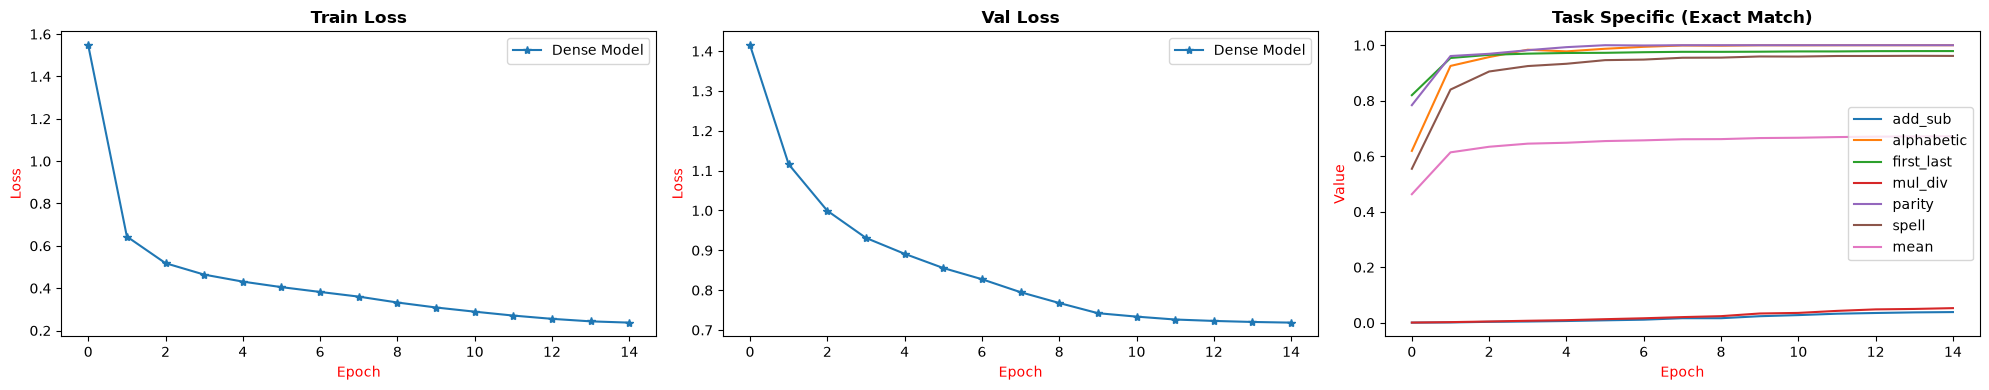

In [22]:
# Define params
params = ["train_loss", "val_loss", "exact_match"]
storages = [evo_dense]
aditional_config = {
                    "titles":["Train Loss", "Val Loss", "Task Specific (Exact Match)"],
                    "names":["Dense Model", "Dense Model", "Dense Model"],
                    "labels": [["Epoch", "Loss"], ["Epoch", "Loss"], ["Epoch", "Value"]],
                    "plot_params": {"marker":'*'},
                    "selected_tasks": None
                }

# Call the function
versus_plotter(storages =  storages, params = params,  aditional_config = aditional_config, filename = 'dense_1.png')

#### **ALTERNATE**

(path) Path (images) exists


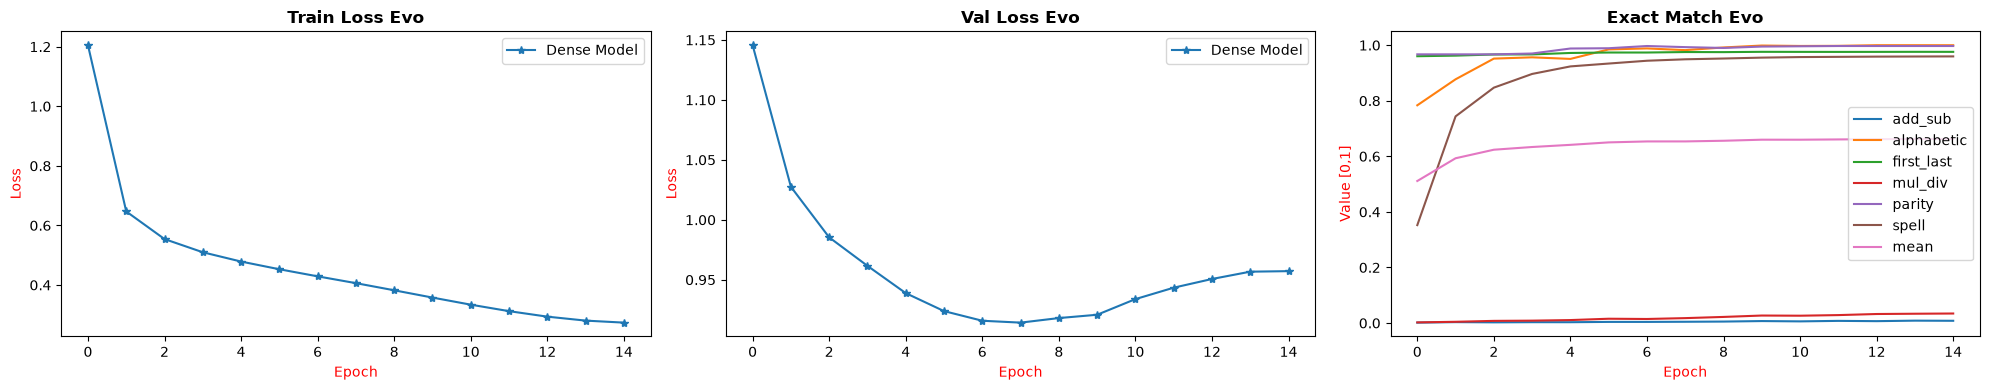

In [23]:
# Define params
params = ["train_loss", "val_loss", "exact_match"]
storages = [full_alternate_evo]
aditional_config = {
                    "titles":["Train Loss Evo", "Val Loss Evo", "Exact Match Evo"],
                    "names":["Dense Model", "Seq Alternate MoE"],
                    "labels": [["Epoch", "Loss"], ["Epoch", "Loss"], ["Epoch", "Value [0,1]"]],
                    "plot_params": {"marker":'*'},
                    "selected_tasks": None

                }

# Call the function
versus_plotter(storages =  storages, params = params,  aditional_config = aditional_config, filename = 'alternate.png')

#### **JOINT ALTERNATE**

(path) Path (images) exists


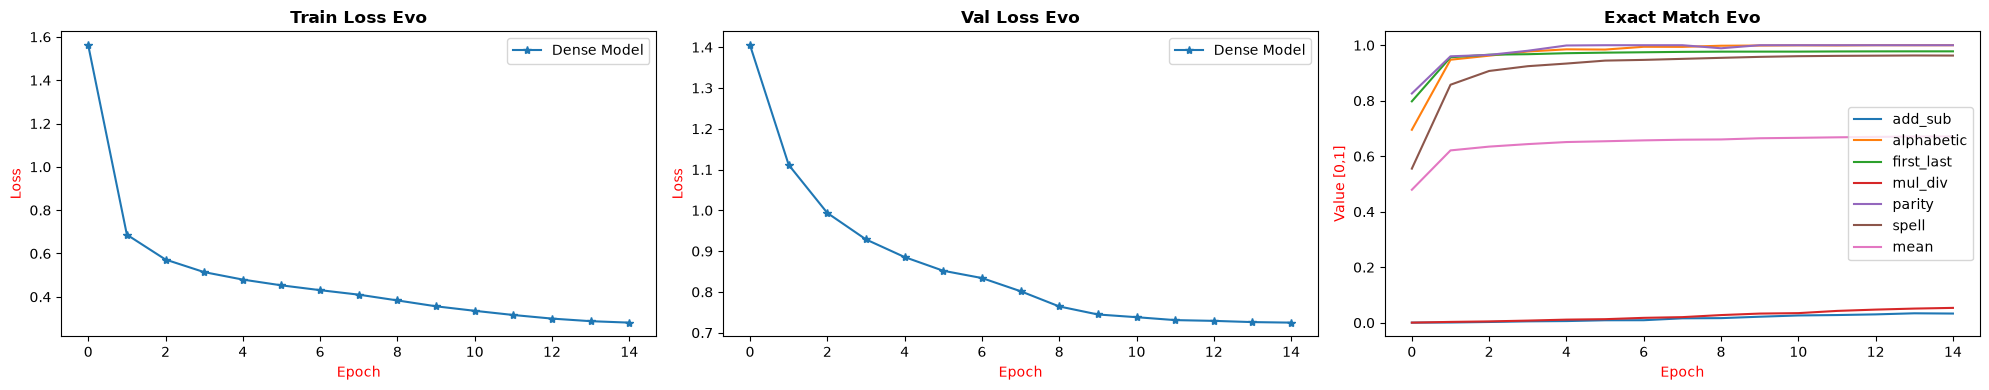

In [24]:
# Define params
params = ["train_loss", "val_loss", "exact_match"]
storages = [full_alternate_joint_evo]
aditional_config = {
                    "titles":["Train Loss Evo", "Val Loss Evo", "Exact Match Evo"],
                    "names":["Dense Model", "Seq Alternate MoE"],
                    "labels": [["Epoch", "Loss"], ["Epoch", "Loss"], ["Epoch", "Value [0,1]"]],
                    "plot_params": {"marker":'*'},
                    "selected_tasks": None

                }

# Call the function
versus_plotter(storages =  storages, params = params,  aditional_config = aditional_config, filename = 'alternate_joint.png')

#### **COMPARISON**

(path) Path (images) exists


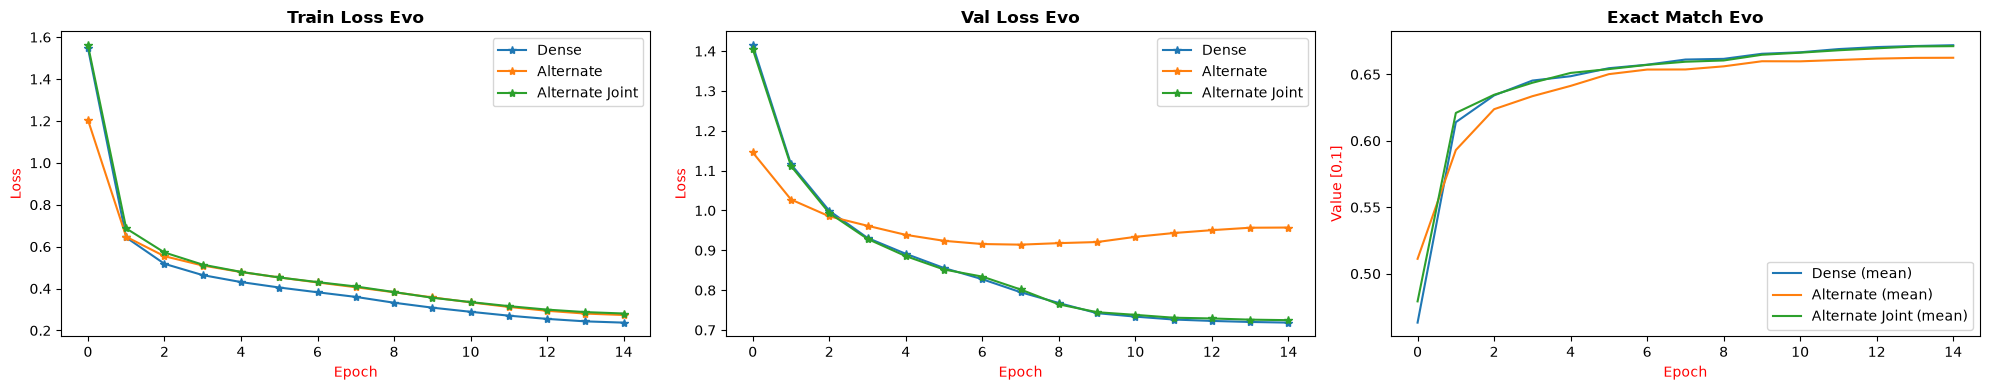

In [26]:
# Define params
params = ["train_loss", "val_loss", "exact_match"]
storages = [evo_dense, full_alternate_evo, full_alternate_joint_evo]
aditional_config = {
                    "titles":["Train Loss Evo", "Val Loss Evo", "Exact Match Evo"],
                    "names":["Dense", "Alternate", "Alternate Joint"],
                    "labels": [["Epoch", "Loss"], ["Epoch", "Loss"], ["Epoch", "Value [0,1]"]],
                    "plot_params": {"marker":'*'},
                    "selected_tasks": ['mean']

                }

# Call the function
versus_plotter(storages =  storages, params = params,  aditional_config = aditional_config, filename = 'test3.png')

## **3. TEST QUALITY EVAL**

In [29]:
def benchmarking(models:list[GPTMOE], modelnames:list[str], context_length:int, device:str, metrics:list[str], tasks:list[str], seed:str)->None:
    """
        Function aimed to conduct benchmarking
        over a given model

        Params:
            model(list(GPTMOE)):
                The list of models
            modelnames(list(str)):
                The name of the models
            device(str):
                The selected device
            context_length(int):
                The length of the context
            metrics(str):
                The metric to use
            seed(str):
                The used seed

            tasks(list(str)):
                The list of tasks to evaluate

        Returns:
            None:
                No value is returned
    """

    # Create the scorer
    scorer = ScorerSelector()

    # Iterate over models
    for  model, modelname in zip(models, modelnames):
        # Info model
        print(f'MODEL({modelname})')
        # Move model to the device
        model.to(device = device)

        # Info seed
        print(f'(bm)Working with seed({seed})')
        # Get the loaders
        tl, vl, tel = Utils.get_loaders(tasks = tasks, batch_size = 64, context_length = context_length, seed = seed)
        print(f'    (dl)({seed}) Aspect of the test loader:', len(tel))
        # Evaluate on the metric
        results = scorer.run(metrics, model = model, loader = tel, device = device)
        print(f'    (results)({seed}) Aspect of results:', results)

        # Create df from results
        print(f'\n(bm)Aspect of the dataframe\n')
        results = pd.DataFrame(results)
        print(results, '\n')

        # Serialize data
        pickler(data = results, path = os.path.join('results', modelname))
        print('\n')

In [28]:
def pickler(data:object, path:str = 'results', base_name = 'results')->None:
    """
        Function aimed to pickle data

        Params:
            data(object):
                The data to pickle
            path(str):
                The path to store data at

        Returns:
            None:
                No value is returned
    """

    # Ensure path
    path_checker(path, create = True)

    # Get next name
    name = Utils.get_next_name(path, key =  base_name, ext = '.pkl')

    # Serialize data
    full_path = os.path.join(path, name)
    with open(full_path, mode = 'wb') as file:
        pkl.dump(data, file)

In [30]:
# Define params
seed = 42
model = {"dense":dense_model, "alternate": full_alternate, "alternate_joint":full_alternate_joint}
tasks = ["add_sub", "mul_div", "alphabetic", "spell", "parity", "first_last"]
context_length = 64


# Call the benchmark per model
benchmarking(models = model.values(), modelnames = model.keys() , context_length = context_length,
            metrics = ["exact_match", "token_ce"], tasks = tasks, seed = seed, device = device)



MODEL(dense)
(bm)Working with seed(42)
    (dl)(42) Aspect of the test loader: 89
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t) Aspect of the mask: torch.Size([64, 54])
(ce_t)

## **4. HYPOTHESIS RELATED EXPERIMENTS**

### **4.1 EXPERT ROUTING HEATMAP**

In [ ]:
def routing_heatmap(models:list[GPTMOE], modelnames:list[str], tasks:list[str], context_length:int, seed:int, device:str, filename:str = None)->None:
    """
        Function aimed to plot, per MoE layer, how often
        the tokens of each task are routed to each expert

        Params:
            models(list(GPTMOE)):
                The list of MoE models
            modelnames(list(str)):
                The name of the models
            tasks(list(str)):
                The list of tasks to evaluate
            context_length(int):
                The length of the context
            seed(int):
                The used seed
            device(str):
                The selected device
            filename(str):
                Name of the stored image
                Default value is None

        Returns:
            None:
                No value is returned
    """
    # Define the base path
    base_path = 'images/router_hmaps'
    # Get the test loader
    _, _, tel = Utils.get_loaders(tasks = tasks, batch_size = 64, context_length = context_length, seed = seed)
    names = tel.dataset.task_names

    task_order = ["add_sub", "mul_div", "alphabetic", "spell", "parity", "first_last"]
    order = [names.index(t) for t in task_order]

    # One row per model, one column per MoE layer
    layers = [i for i, use_moe in enumerate(models[0].moe_mask) if use_moe]
    fig, axes = plt.subplots(len(models), len(layers), figsize = (5*len(layers), 4*len(models)), squeeze = False)

    # Plot each model
    for row, model, modelname in zip(axes, models, modelnames):
        # Move model to the device
        model.to(device = device)
        # Get the routing distributions (layers, tasks, experts): tokens distribution per task over experts
        matrix = routing_matrix(model, tel, device)

        # Plot each layer
        for ax, layer, distribution in zip(row, layers, matrix):
            # Generate heatmap
            sb.heatmap(distribution[order].numpy(), ax = ax, vmin = 0, vmax = 1, cmap = 'magma',
                        annot = True, fmt = '.2f', cbar = True, xticklabels = [f'E{i}' for i in range(distribution.shape[1])],
                        yticklabels = [names[i] for i in order])

            # Enhance the plot
            ax.set_title(f'{modelname} (layer {layer})', fontweight = 'bold')
            ax.set_xlabel('Expert', color = 'red')

    # Tight the plot
    plt.tight_layout()

    # Store the figure
    if filename:
        # Ensure path
        path_checker(path = base_path, create = True)
        # Save the fig
        plt.savefig(os.path.join(base_path, filename), dpi = 600)

(path) Path (images/router_hmaps) exists


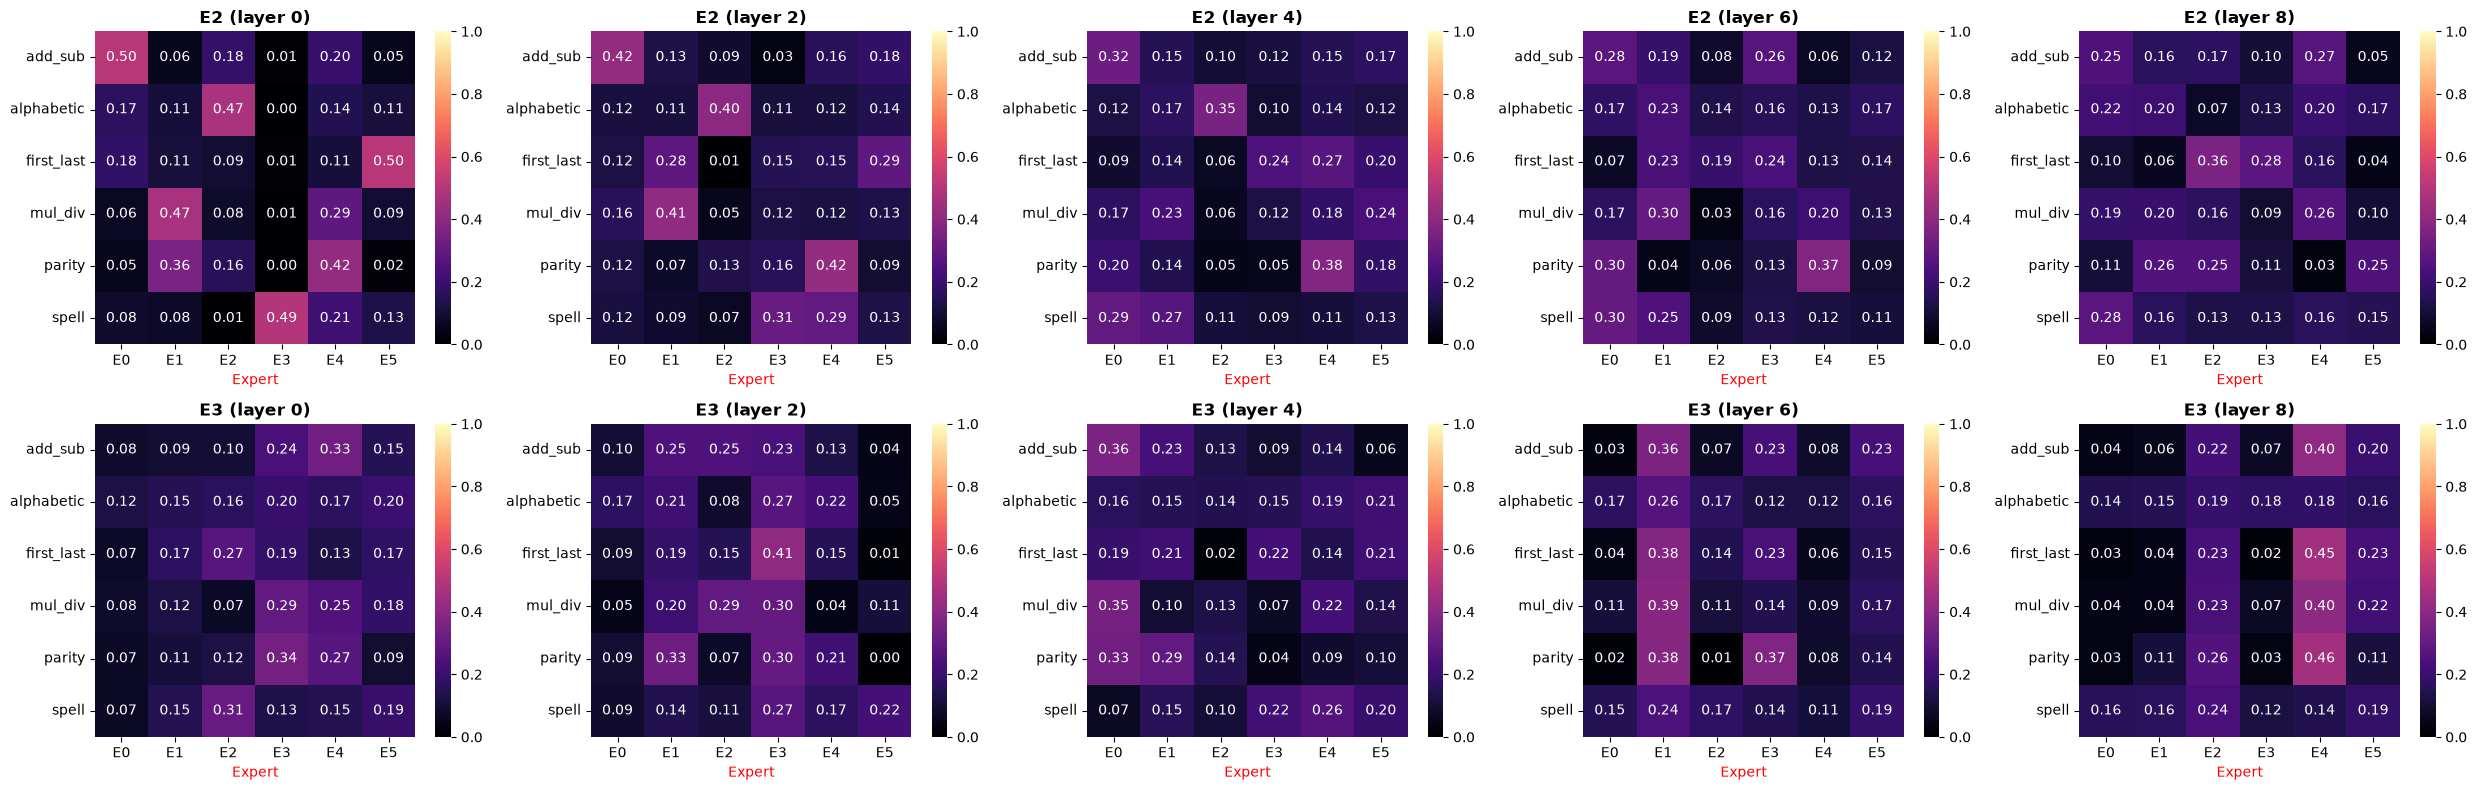

In [111]:
# Define params
seed = 42
context_length = 64
models = {"E2": full_alternate, "E3": full_alternate_joint}
tasks = ["add_sub", "mul_div", "alphabetic", "spell", "parity", "first_last"]


# Call the function
routing_heatmap(models = list(models.values()), modelnames = list(models.keys()), tasks = tasks,
                context_length = context_length, seed = seed, device = device, filename = 'routing_heatmap.png')

### **4.2 TOKEN TRACE**

In [ ]:
def token_trace(model:GPTMOE, prompt:str, task:str, device:str, max_new:int = 30, filename:str = None, input_ids: torch.Tensor = None)->pd.DataFrame:
    """
        Function aimed to follow a single example token by
        token and show the top-1 expert chosen in every MoE layer

        Params:
            model(GPTMOE):
                The model to inspect
            prompt(str):
                The raw prompt (without task name)
            task(str):
                The task name
            device(str):
                The selected device
            max_new(int):
                Max amount of generated tokens
                Default value is 30
            filename(str):
                Name of the stored image
                Default value is None

            input_ids(list(int)):
                The list containing input ids

        Returns:
            trace(pd.DataFrame):
                Top-1 expert per layer (rows) and token (cols)
    """
    # Build the tokenizer and the prompt as in training
    tokenizer = Tokenizer(embedding_dim = 768, max_seq_len = model.pos_emb.num_embeddings)
    if input_ids is None:
        prompt_ids = torch.tensor(tokenizer.encode(TaskDataset.build_prompt(prompt, task)), device = device)
    else:
        prompt_ids = input_ids
    eos_id = tokenizer.tokenizer.eot_token

    # Generate the answer with greedy decoding (1, N)
    model.to(device = device)
    model.eval()
    with torch.no_grad():
        answer_ids = greedy_answer(model, prompt_ids, eos_id, max_new = max_new)



    # Route the full sequence (prompt + answer) at once
    ids = torch.cat([prompt_ids, torch.tensor(answer_ids, dtype = prompt_ids.dtype, device = device)]).unsqueeze(0)
    # Retrieve per layer router aspect (1, N, K)
    routes = route(model, ids, device)

    # Debug info
    print('DEBUG')
    print('·Input shape:', prompt_ids.shape)
    print('·Output shape:', torch.tensor(answer_ids).shape)
    print('·Cat shape:', ids.shape)
    print('·Routes shape:', routes[0].shape)

    # Build the trace -> rows: MoE layers, cols: tokens
    # Decode (N, )
    tokens = [tokenizer.decode([i]) for i in ids[0].tolist()]
    # Generate df
    k_val = 1
    trace = pd.DataFrame([selected[0, :, k_val - 1].numpy() for selected in routes.values()],
                            index = [f'L{layer}' for layer in routes])

    # Plot the trace -> one color per expert
    n_exp = model.moe_layers()[0].n_exp
    # Define the figure
    fig, ax = plt.subplots(figsize = (0.6*len(tokens), 3))
    # Create heatmap
    sb.heatmap(trace, ax = ax, annot = True, cbar = False, cmap = sb.color_palette('tab10', n_exp), xticklabels = tokens)
    # Enhance the plot
    ax.set_title(f'{task}: {prompt}', fontweight = 'bold')
    plt.tight_layout()

    # Store the figure
    if filename:
        path_checker(path = 'images', create = True)
        plt.savefig(os.path.join('images', filename), dpi = 600)

    return trace

**Add_sub**

DEBUG
·Input shape: torch.Size([8])
·Output shape: torch.Size([1])
·Cat shape: torch.Size([1, 9])
·Routes shape: torch.Size([1, 9, 2])
DEBUG
·Input shape: torch.Size([8])
·Output shape: torch.Size([1])
·Cat shape: torch.Size([1, 9])
·Routes shape: torch.Size([1, 9, 2])


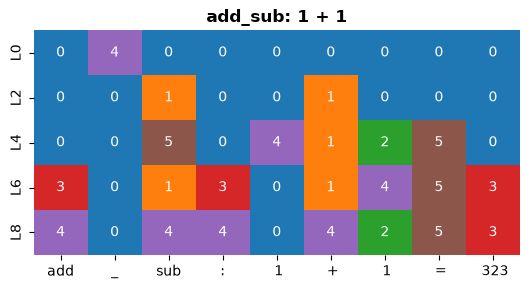

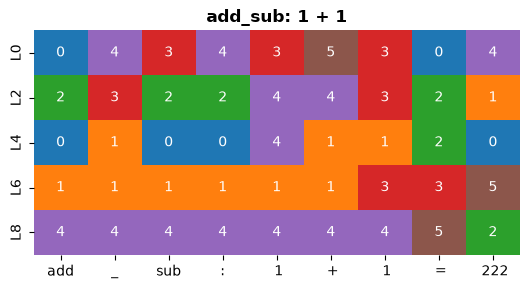

In [222]:
# Define params
example = {"prompt": "1 + 1", "task": "add_sub"}

# Call the function per model
for modelname, model in models.items():
    token_trace(model = model, device = device, filename = f'trace_add_sub{modelname}.png', **example)

**Alphabetic**

DEBUG
·Input shape: torch.Size([7])
·Output shape: torch.Size([1])
·Cat shape: torch.Size([1, 8])
·Routes shape: torch.Size([1, 8, 2])
DEBUG
·Input shape: torch.Size([7])
·Output shape: torch.Size([3])
·Cat shape: torch.Size([1, 10])
·Routes shape: torch.Size([1, 10, 2])


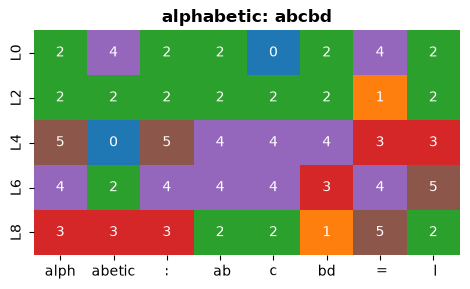

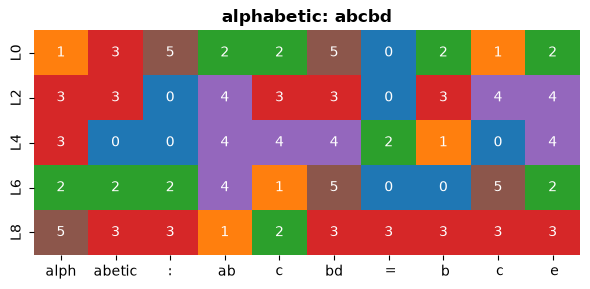

In [221]:
# Define params
example = {"prompt": "abcbd", "task": "alphabetic"}

# Call the function per model
for modelname, model in models.items():
    token_trace(model = model, device = device, filename = f'trace_alphabetic{modelname}.png', **example)

**First Last**

DEBUG
·Input shape: torch.Size([8])
·Output shape: torch.Size([2])
·Cat shape: torch.Size([1, 10])
·Routes shape: torch.Size([1, 10, 2])
DEBUG
·Input shape: torch.Size([8])
·Output shape: torch.Size([2])
·Cat shape: torch.Size([1, 10])
·Routes shape: torch.Size([1, 10, 2])


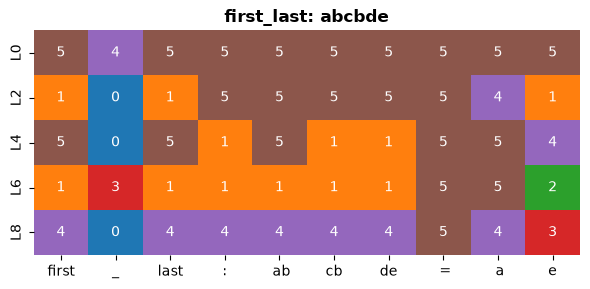

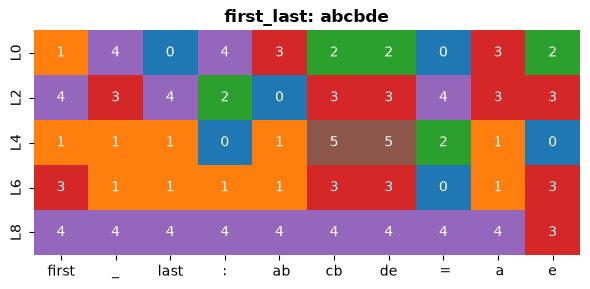

In [223]:
# Define params
example = {"prompt": "abcbde", "task": "first_last"}

# Call the function per model
for modelname, model in models.items():
    token_trace(model = model, device = device, filename = f'trace_first_last{modelname}.png', **example)

**Mul Div**

DEBUG
·Input shape: torch.Size([9])
·Output shape: torch.Size([2])
·Cat shape: torch.Size([1, 11])
·Routes shape: torch.Size([1, 11, 2])
DEBUG
·Input shape: torch.Size([9])
·Output shape: torch.Size([2])
·Cat shape: torch.Size([1, 11])
·Routes shape: torch.Size([1, 11, 2])


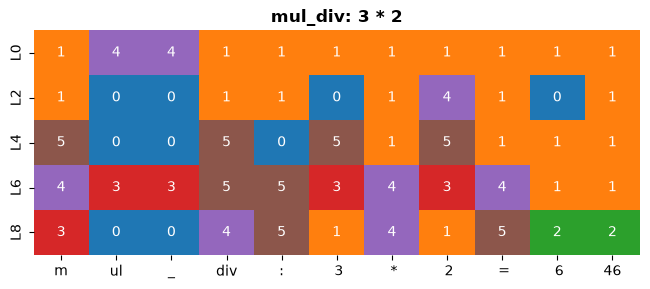

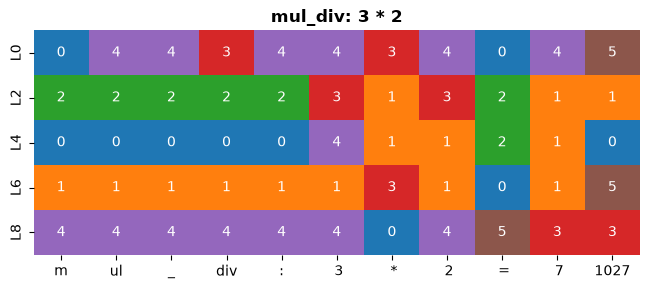

In [224]:
# Define params
example = {"prompt": "3 * 2", "task": "mul_div"}

# Call the function per model
for modelname, model in models.items():
    token_trace(model = model, device = device, filename = f'trace_mul_div{modelname}.png', **example)

**Parity**

DEBUG
·Input shape: torch.Size([5])
·Output shape: torch.Size([1])
·Cat shape: torch.Size([1, 6])
·Routes shape: torch.Size([1, 6, 2])
DEBUG
·Input shape: torch.Size([5])
·Output shape: torch.Size([1])
·Cat shape: torch.Size([1, 6])
·Routes shape: torch.Size([1, 6, 2])


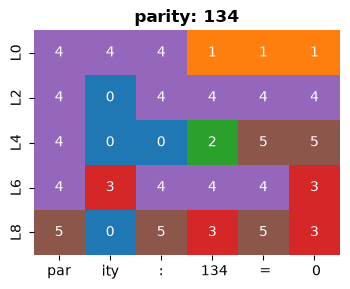

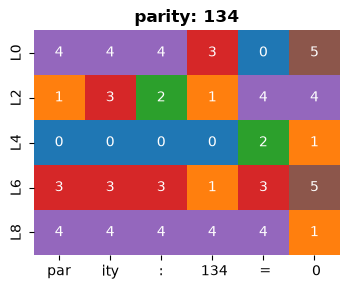

In [225]:
# Define params
example = {"prompt": "134", "task": "parity"}

# Call the function per model
for modelname, model in models.items():
    token_trace(model = model, device = device, filename = f'trace_parity{modelname}.png', **example)

**Spell**

DEBUG
·Input shape: torch.Size([6])
·Output shape: torch.Size([5])
·Cat shape: torch.Size([1, 11])
·Routes shape: torch.Size([1, 11, 2])
DEBUG
·Input shape: torch.Size([6])
·Output shape: torch.Size([5])
·Cat shape: torch.Size([1, 11])
·Routes shape: torch.Size([1, 11, 2])


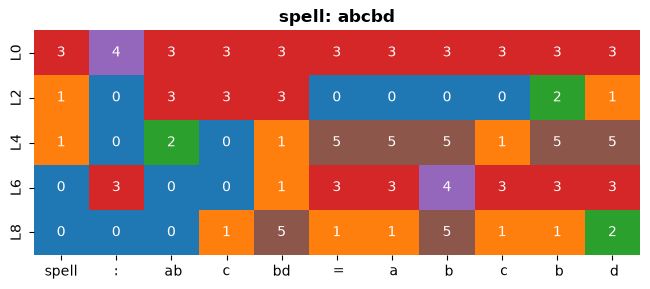

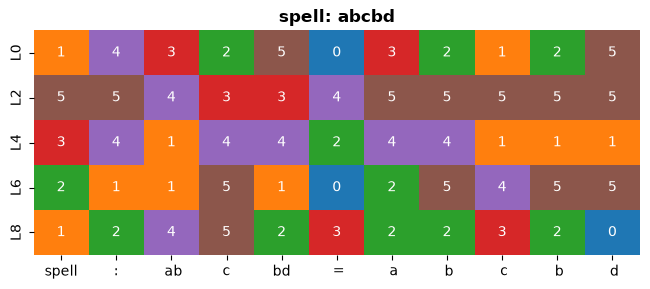

In [226]:
# Define params
example = {"prompt": "abcbd", "task": "spell"}

# Call the function per model
for modelname, model in models.items():
    token_trace(model = model, device = device, filename = f'trace_spell{modelname}.png', **example)

### **4.3 ATTENTION ASPECT**

#### **ATT HEATMAPS AND MOST ATTENDED TOKENS**

In [ ]:
def get_most_attented_tokens(data:torch.Tensor, k:int, labels:list[str])->dict:

    """
        Function aimed to return the most
        attented tokens on avg

        Params:
            data(torch.Tensor):
                The attention matrix of shape (H, N, N)
                where N is the amount of tokens

            k(int):
                The size of the top to consider

            labels(list(str)):
                The string mappings to the generated tokens

        Returns:
            storage(dict(str:object)):
                A dictionar


    """
     # Average attention across heads (N, N)
    mean_att = data.mean(dim=0)

    # Attention received by each token: (N,)
    raw_per_token_att = mean_att.sum(dim=0)
    received_att = raw_per_token_att/raw_per_token_att.sum()

    # Rank tokens from highest to lowest attention received
    ranking = torch.argsort(received_att, descending=True)
    selected_positions = ranking[:3].tolist()
    # Print the ranking
    top_tokens = [
                    {
                        "position":idx,
                        "token":labels[idx],
                        "att":received_att[idx]
                    }


                    for idx in selected_positions]

    print('DEBUG (get_most_attented_tokens)')
    for token in top_tokens:
        print(f'TOKEN -->{token}')

    return top_tokens

In [ ]:
def track_attention(model:GPTMOE, modelname:str, pairs:list[str], layer:int, device:str, max_new:int = 30, filename:str = None)->None:

    """
        Function aimed to track attention
        mechanism accross the different
        layers

        Params:
            model(GPTMOE):
                The selected model
            modelname(str):
                The name of the model
            pairs(list(tuple(str, str))):
                The list of (prompt, task) pair
            layer(int):
                The layer to track
        Returns:
            attention_results(list(list(dict)))
                List of top-k attended tokens
                per task
    """

    # Define the base path
    base_path = 'images/att_hmaps'
    # Build the tokenizer
    tokenizer = Tokenizer(embedding_dim = 768, max_seq_len = model.pos_emb.num_embeddings)
    print(f'ATTENTION EXPERIMENT')

    # Define structured
    att_matrices_storage = []
    attention_results = []
    labels_storage = []
    heads = 8

    # Iterate per (task, prompt) pair
    for task, prompt in pairs:
        # Info print
        print(f' Dealing with ({task}: {prompt})')
        # Get prompt
        prompt_ids = torch.tensor(tokenizer.encode(TaskDataset.build_prompt(prompt, task)), device = device)
        eos_id = tokenizer.tokenizer.eot_token

        # Get labels for later plotting -> remember that tokenizer returns full str
        labels = [tokenizer.decode([token]) for token in prompt_ids]
        print(f'    ·Aspect of labels -> {(labels)}')
        print(f'    ·Shape of labels -> {labels.__len__()}')


        # Generate the answer with greedy decoding (1, N)
        model.to(device = device)
        model.eval()
        with torch.no_grad():
            model(prompt_ids.unsqueeze(0))

        # Retrieve att matrices
        att_matrices = model.attn_mechanism()[layer].squeeze(0)
        print(f'  ·Aspect of the att weights:', att_matrices.shape)

        # Get top-k visited tokens
        attention_results.append(get_most_attented_tokens(data = att_matrices, k = 3, labels = labels))


        # Split by head
        splitted_att = [att_matrices[i, :,:]  for i in range(heads)]

        # Store att and linked labels
        att_matrices_storage.append(att_matrices)
        labels_storage.append(labels)

    # Conduct hmap building
    print('\nPLOTTING FASE')
    print(f" ·Labels:{labels_storage}")
    print(f" ·Att storage:{len(att_matrices_storage)}")

    # Define fig
    n = len(att_matrices_storage)
    fig, axes = plt.subplots(n, heads, figsize = (4*heads, 4*n), squeeze = False)

    # Iterate per tasks
    for i in range(n):
        # Get labels
        iter_labels = labels_storage[i]
        # Iterate over heads
        for j  in range(heads):
            # Graph each head
            sb.heatmap(data =  att_matrices_storage[i][j] , ax = axes[i,j],
                       xticklabels = iter_labels, cmap = "magma", yticklabels = iter_labels)

            # Define title
            axes[i, j].set_title(f' Head ({j})', fontweight = 'bold')

    # Tight layout
    plt.tight_layout()

    # Check saving
    if filename is not None:
        # Create path
        path = os.path.join(base_path, modelname)
        # Check path
        path_checker(path = path, create = True)
        # Save fig
        plt.savefig(os.path.join(path, filename), dpi = 600)


    # Show the image
    plt.show()

    return attention_results

WORKING WITH (E2)
ATTENTION EXPERIMENT
 Dealing with (add_sub: 1 + 1)
    ·Aspect of labels -> ['add', '_', 'sub', ':', ' 1', ' +', ' 1', ' =']
    ·Shape of labels -> 8
  ·Aspect of the att weights: torch.Size([8, 8, 8])
DEBUG (get_most_attented_tokens)
TOKEN -->{'position': 0, 'token': 'add', 'att': tensor(0.3397)}
TOKEN -->{'position': 1, 'token': '_', 'att': tensor(0.2527)}
TOKEN -->{'position': 2, 'token': 'sub', 'att': tensor(0.1308)}
 Dealing with (spell: abcd)
    ·Aspect of labels -> ['spell', ':', ' ab', 'cd', ' =']
    ·Shape of labels -> 5
  ·Aspect of the att weights: torch.Size([8, 5, 5])
DEBUG (get_most_attented_tokens)
TOKEN -->{'position': 0, 'token': 'spell', 'att': tensor(0.4643)}
TOKEN -->{'position': 1, 'token': ':', 'att': tensor(0.2969)}
TOKEN -->{'position': 2, 'token': ' ab', 'att': tensor(0.1480)}

PLOTTING FASE
 ·Labels:[['add', '_', 'sub', ':', ' 1', ' +', ' 1', ' ='], ['spell', ':', ' ab', 'cd', ' =']]
 ·Att storage:2


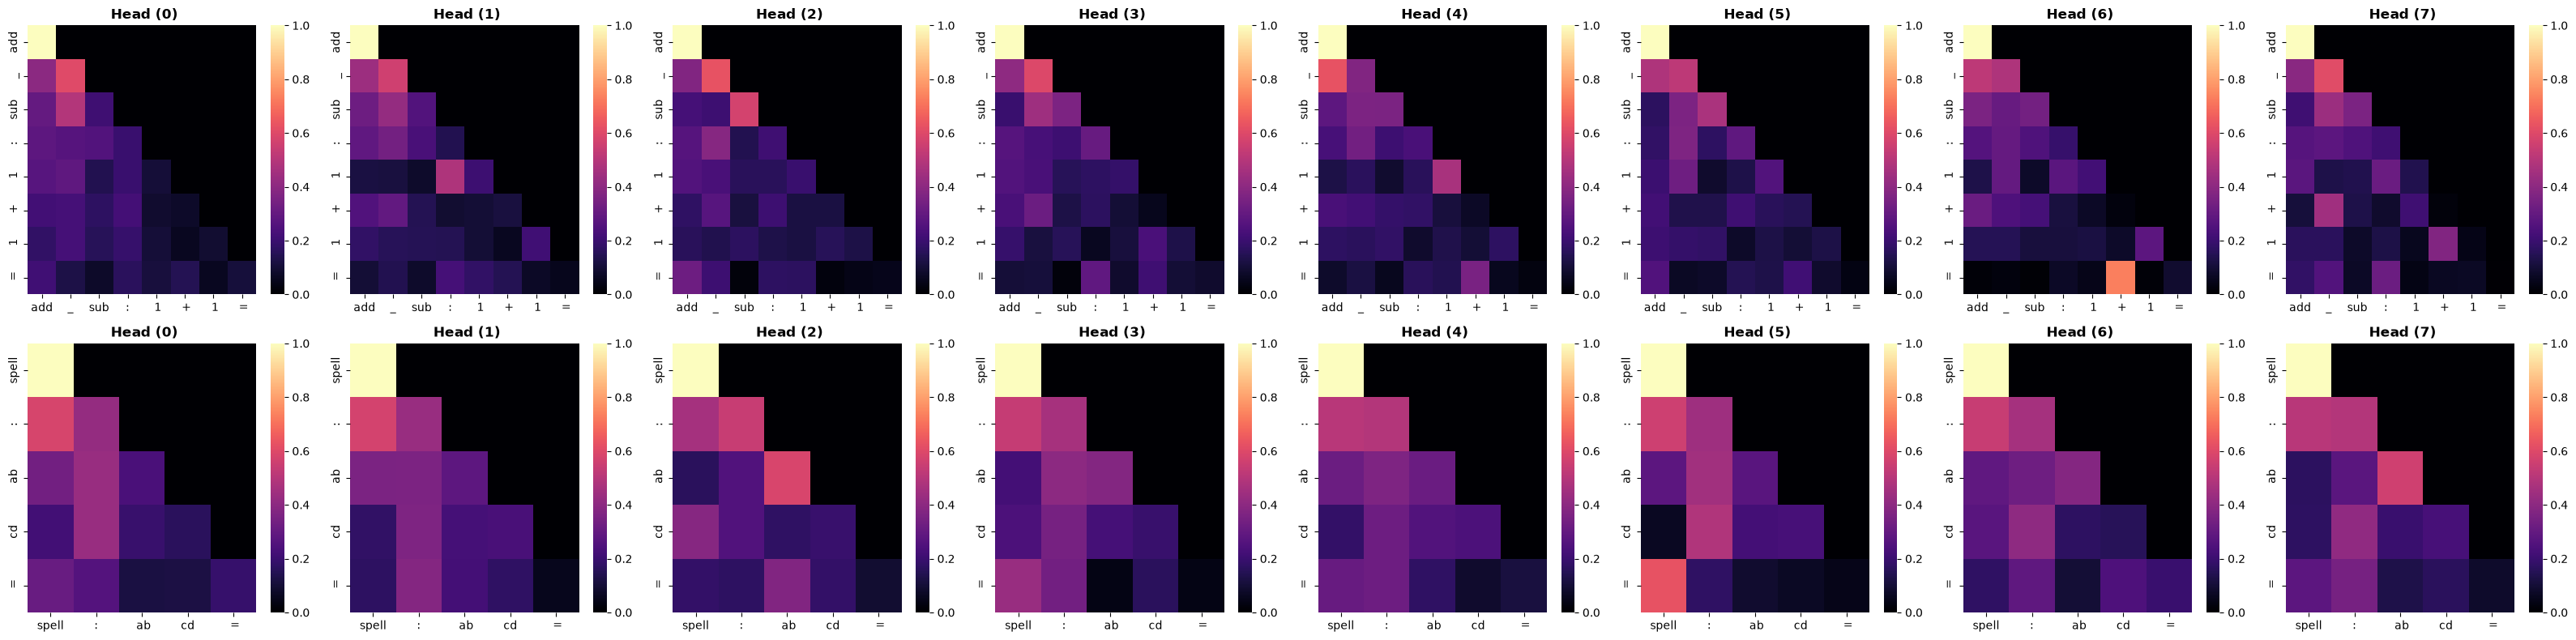

attention_results: [[{'position': 0, 'token': 'add', 'att': tensor(0.3397)}, {'position': 1, 'token': '_', 'att': tensor(0.2527)}, {'position': 2, 'token': 'sub', 'att': tensor(0.1308)}], [{'position': 0, 'token': 'spell', 'att': tensor(0.4643)}, {'position': 1, 'token': ':', 'att': tensor(0.2969)}, {'position': 2, 'token': ' ab', 'att': tensor(0.1480)}]]
ATTENTION EXPERIMENT
 Dealing with (add_sub: 1 + 1)
    ·Aspect of labels -> ['add', '_', 'sub', ':', ' 1', ' +', ' 1', ' =']
    ·Shape of labels -> 8
  ·Aspect of the att weights: torch.Size([8, 8, 8])
DEBUG (get_most_attented_tokens)
TOKEN -->{'position': 0, 'token': 'add', 'att': tensor(0.3365)}
TOKEN -->{'position': 1, 'token': '_', 'att': tensor(0.2424)}
TOKEN -->{'position': 4, 'token': ' 1', 'att': tensor(0.1188)}
 Dealing with (spell: abcd)
    ·Aspect of labels -> ['spell', ':', ' ab', 'cd', ' =']
    ·Shape of labels -> 5
  ·Aspect of the att weights: torch.Size([8, 5, 5])
DEBUG (get_most_attented_tokens)
TOKEN -->{'positio

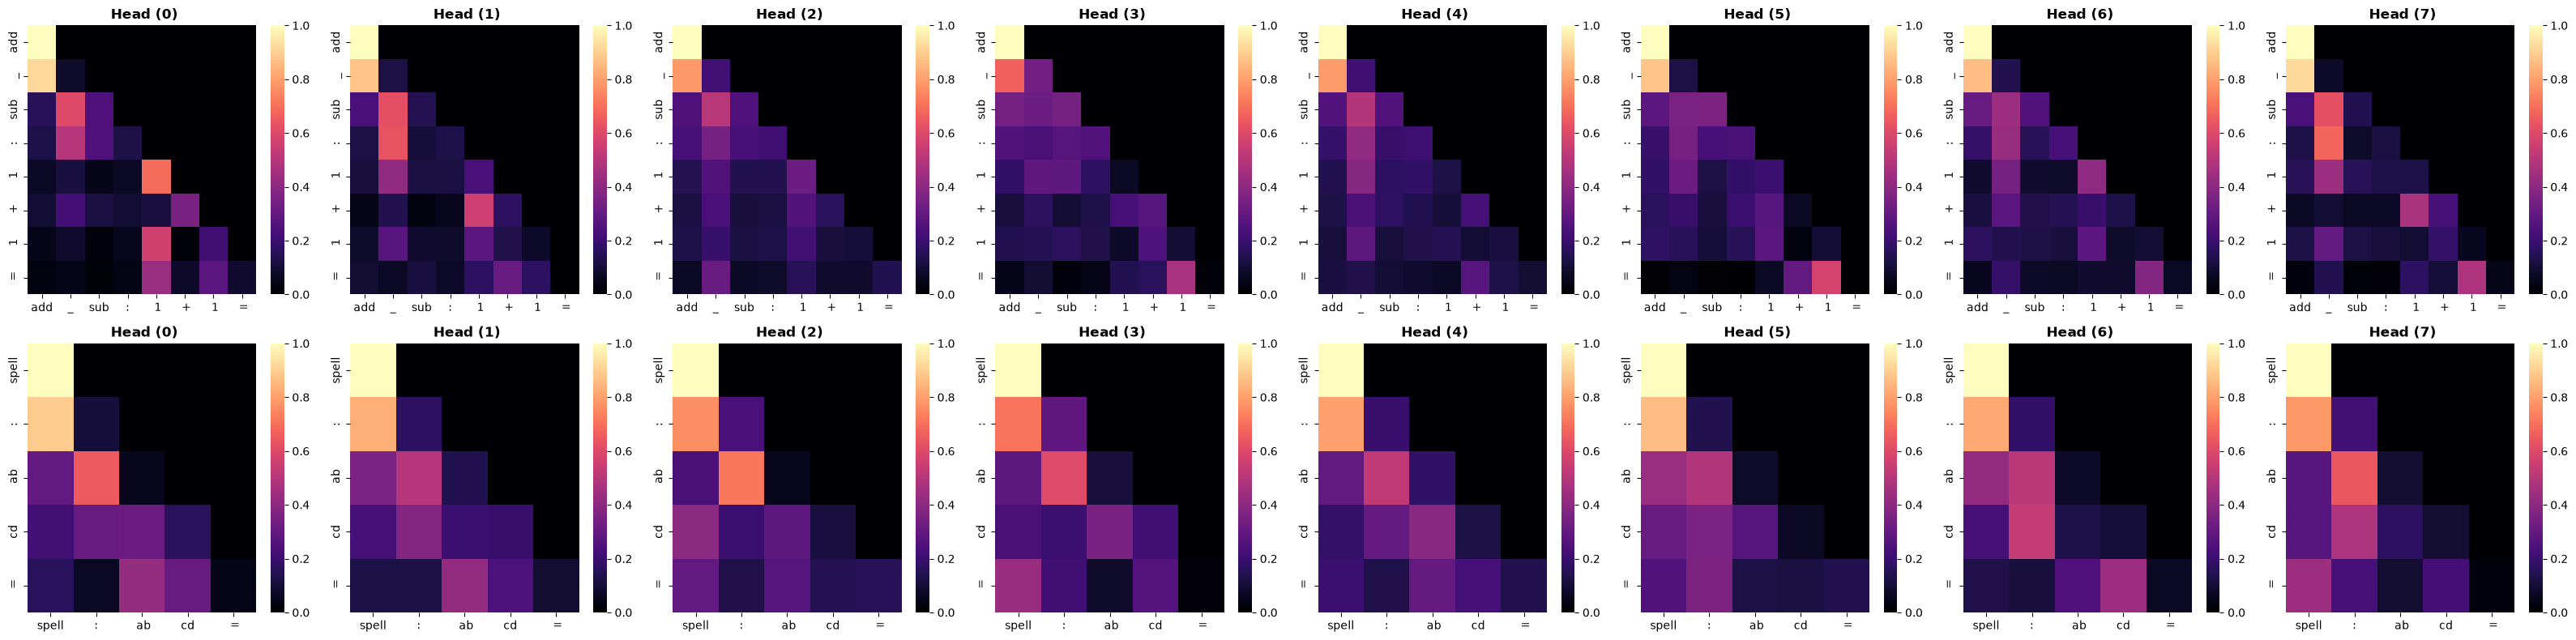

attention_results: [[{'position': 0, 'token': 'add', 'att': tensor(0.3365)}, {'position': 1, 'token': '_', 'att': tensor(0.2424)}, {'position': 4, 'token': ' 1', 'att': tensor(0.1188)}], [{'position': 0, 'token': 'spell', 'att': tensor(0.5285)}, {'position': 1, 'token': ':', 'att': tensor(0.2574)}, {'position': 2, 'token': ' ab', 'att': tensor(0.1209)}]]
ATTENTION EXPERIMENT
 Dealing with (add_sub: 1 + 1)
    ·Aspect of labels -> ['add', '_', 'sub', ':', ' 1', ' +', ' 1', ' =']
    ·Shape of labels -> 8
  ·Aspect of the att weights: torch.Size([8, 8, 8])
DEBUG (get_most_attented_tokens)
TOKEN -->{'position': 0, 'token': 'add', 'att': tensor(0.3473)}
TOKEN -->{'position': 1, 'token': '_', 'att': tensor(0.2019)}
TOKEN -->{'position': 2, 'token': 'sub', 'att': tensor(0.1388)}
 Dealing with (spell: abcd)
    ·Aspect of labels -> ['spell', ':', ' ab', 'cd', ' =']
    ·Shape of labels -> 5
  ·Aspect of the att weights: torch.Size([8, 5, 5])
DEBUG (get_most_attented_tokens)
TOKEN -->{'positio

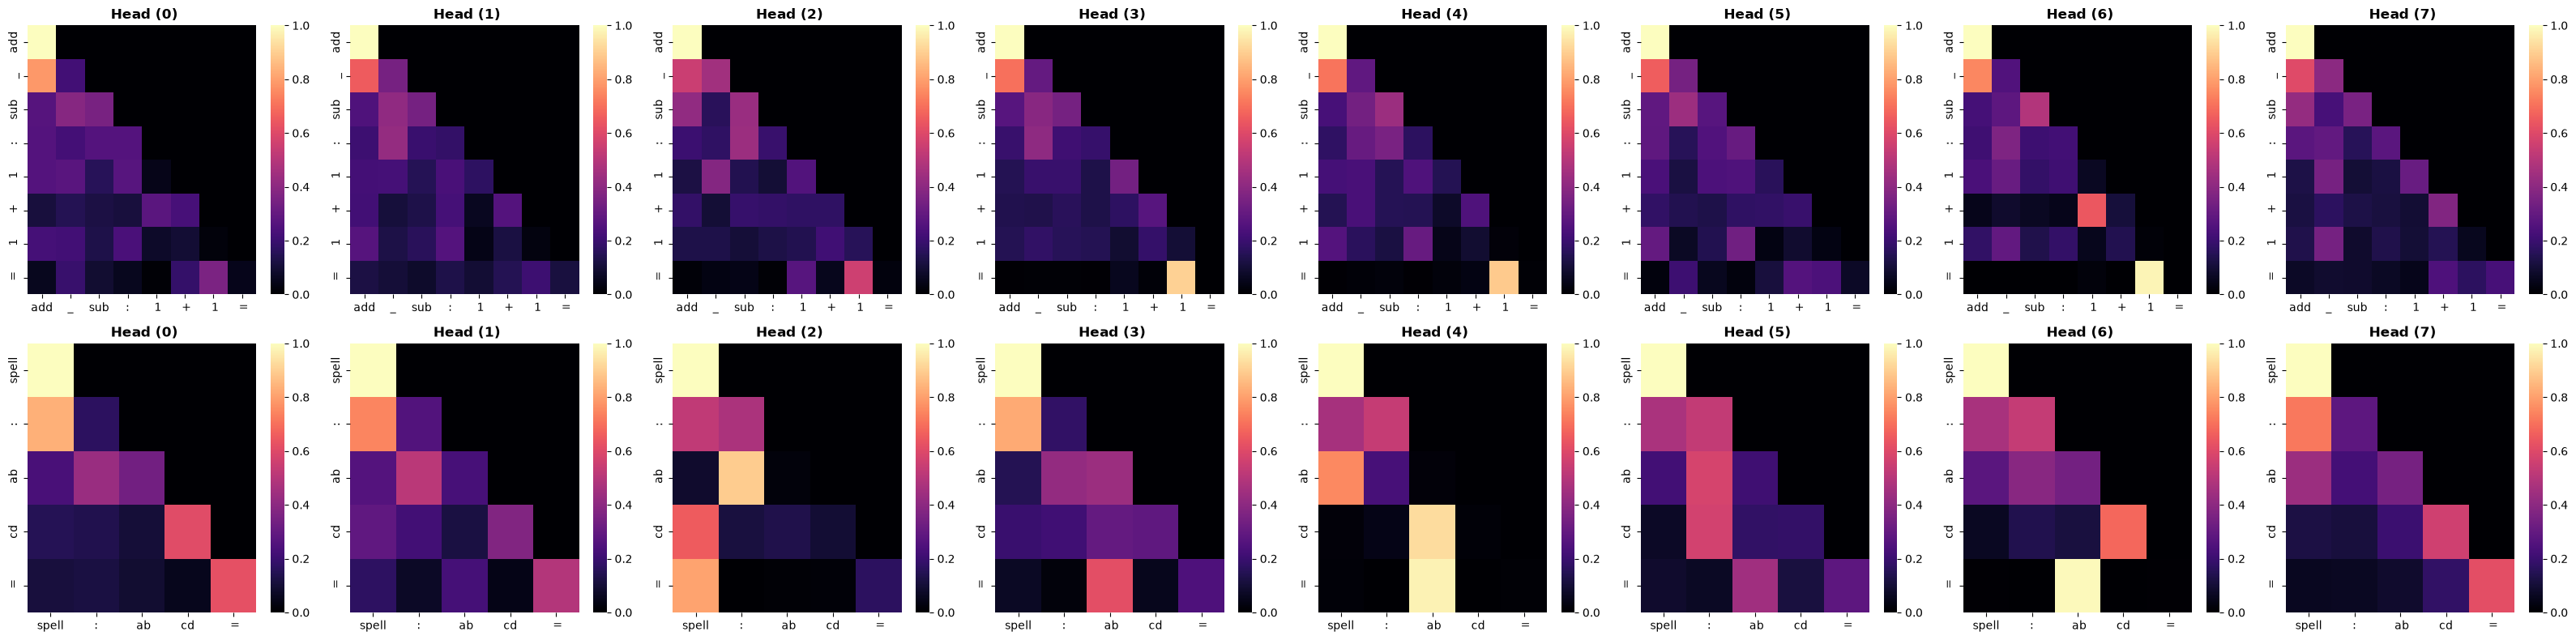

attention_results: [[{'position': 0, 'token': 'add', 'att': tensor(0.3473)}, {'position': 1, 'token': '_', 'att': tensor(0.2019)}, {'position': 2, 'token': 'sub', 'att': tensor(0.1388)}], [{'position': 0, 'token': 'spell', 'att': tensor(0.4586)}, {'position': 1, 'token': ':', 'att': tensor(0.2127)}, {'position': 2, 'token': ' ab', 'att': tensor(0.1862)}]]
ATTENTION EXPERIMENT
 Dealing with (add_sub: 1 + 1)
    ·Aspect of labels -> ['add', '_', 'sub', ':', ' 1', ' +', ' 1', ' =']
    ·Shape of labels -> 8
  ·Aspect of the att weights: torch.Size([8, 8, 8])
DEBUG (get_most_attented_tokens)
TOKEN -->{'position': 0, 'token': 'add', 'att': tensor(0.3178)}
TOKEN -->{'position': 1, 'token': '_', 'att': tensor(0.2248)}
TOKEN -->{'position': 2, 'token': 'sub', 'att': tensor(0.1619)}
 Dealing with (spell: abcd)
    ·Aspect of labels -> ['spell', ':', ' ab', 'cd', ' =']
    ·Shape of labels -> 5
  ·Aspect of the att weights: torch.Size([8, 5, 5])
DEBUG (get_most_attented_tokens)
TOKEN -->{'positi

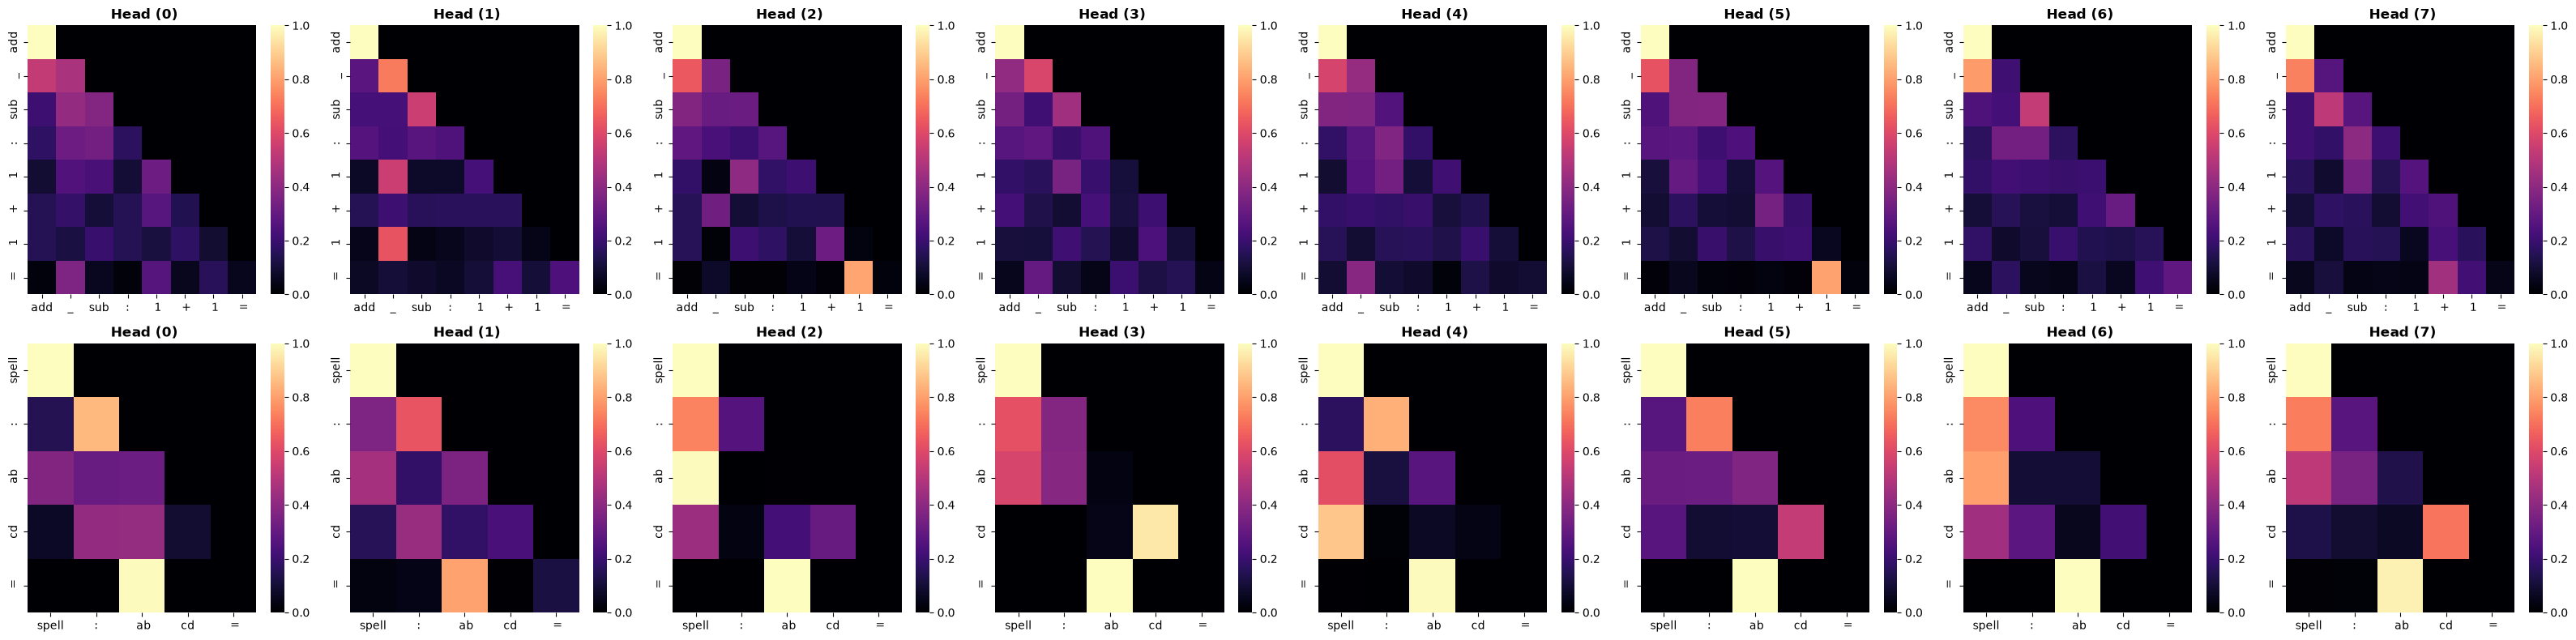

attention_results: [[{'position': 0, 'token': 'add', 'att': tensor(0.3178)}, {'position': 1, 'token': '_', 'att': tensor(0.2248)}, {'position': 2, 'token': 'sub', 'att': tensor(0.1619)}], [{'position': 0, 'token': 'spell', 'att': tensor(0.4723)}, {'position': 2, 'token': ' ab', 'att': tensor(0.2626)}, {'position': 1, 'token': ':', 'att': tensor(0.1848)}]]
ATTENTION EXPERIMENT
 Dealing with (add_sub: 1 + 1)
    ·Aspect of labels -> ['add', '_', 'sub', ':', ' 1', ' +', ' 1', ' =']
    ·Shape of labels -> 8
  ·Aspect of the att weights: torch.Size([8, 8, 8])
DEBUG (get_most_attented_tokens)
TOKEN -->{'position': 0, 'token': 'add', 'att': tensor(0.3342)}
TOKEN -->{'position': 1, 'token': '_', 'att': tensor(0.1997)}
TOKEN -->{'position': 2, 'token': 'sub', 'att': tensor(0.1297)}
 Dealing with (spell: abcd)
    ·Aspect of labels -> ['spell', ':', ' ab', 'cd', ' =']
    ·Shape of labels -> 5
  ·Aspect of the att weights: torch.Size([8, 5, 5])
DEBUG (get_most_attented_tokens)
TOKEN -->{'positi

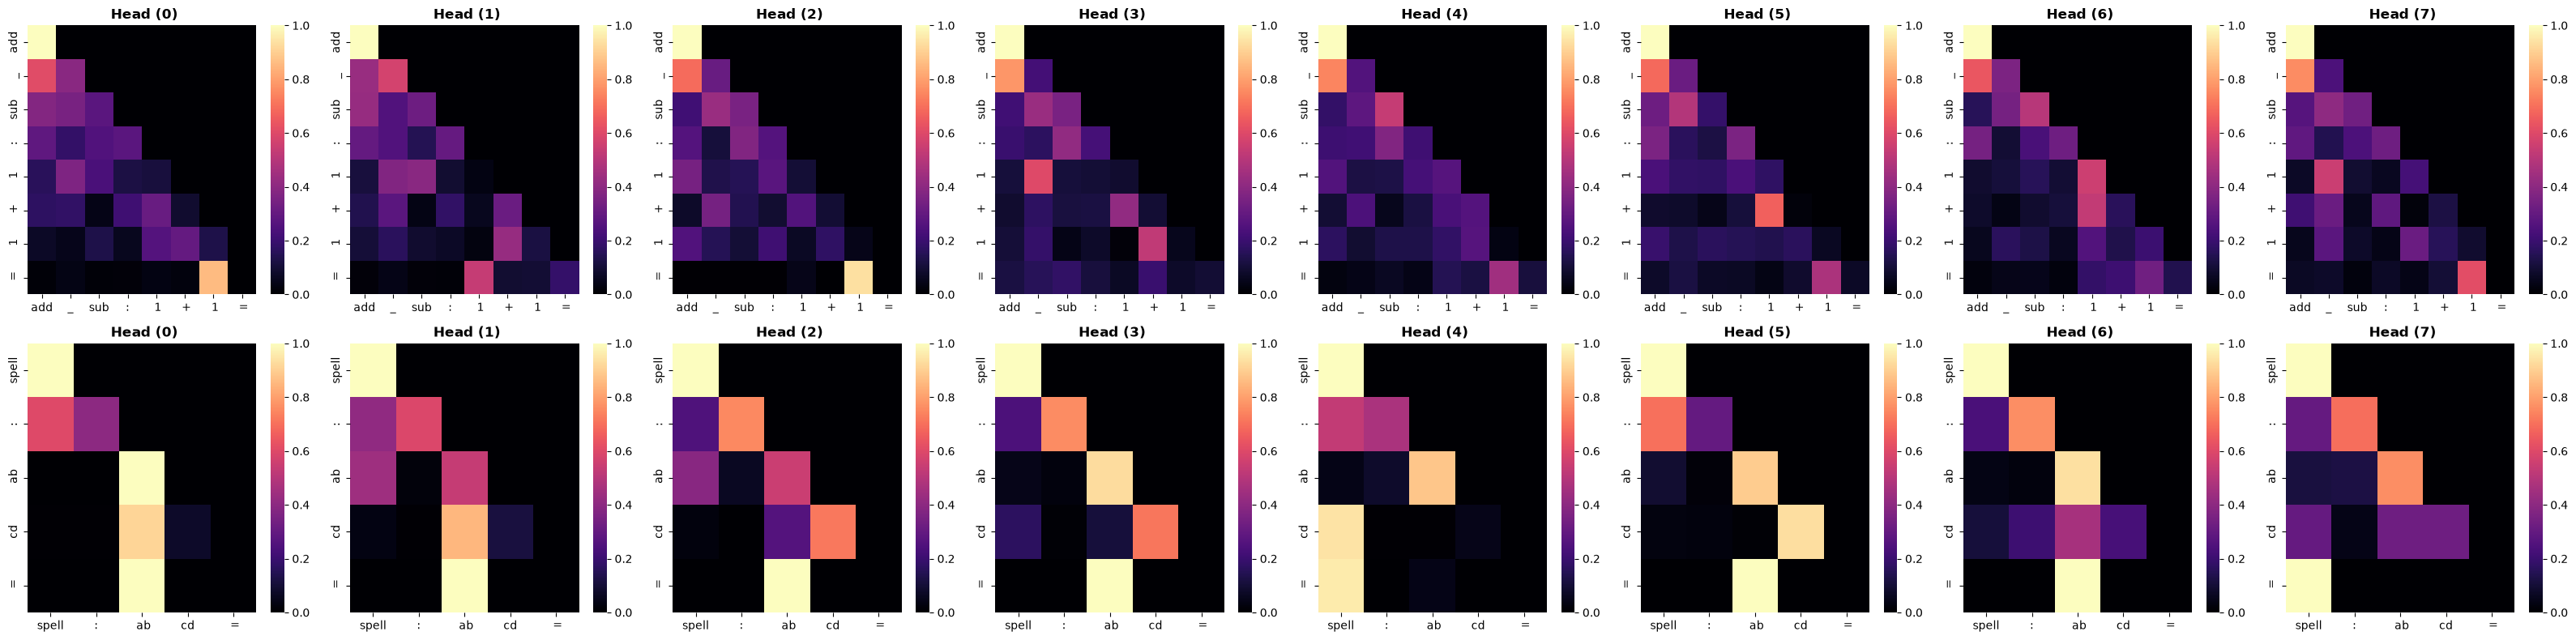

attention_results: [[{'position': 0, 'token': 'add', 'att': tensor(0.3342)}, {'position': 1, 'token': '_', 'att': tensor(0.1997)}, {'position': 2, 'token': 'sub', 'att': tensor(0.1297)}], [{'position': 0, 'token': 'spell', 'att': tensor(0.4003)}, {'position': 2, 'token': ' ab', 'att': tensor(0.3860)}, {'position': 1, 'token': ':', 'att': tensor(0.1349)}]]
WORKING WITH (E3)
ATTENTION EXPERIMENT
 Dealing with (add_sub: 1 + 1)
    ·Aspect of labels -> ['add', '_', 'sub', ':', ' 1', ' +', ' 1', ' =']
    ·Shape of labels -> 8
  ·Aspect of the att weights: torch.Size([8, 8, 8])
DEBUG (get_most_attented_tokens)
TOKEN -->{'position': 0, 'token': 'add', 'att': tensor(0.3345)}
TOKEN -->{'position': 1, 'token': '_', 'att': tensor(0.2367)}
TOKEN -->{'position': 2, 'token': 'sub', 'att': tensor(0.1505)}
 Dealing with (spell: abcd)
    ·Aspect of labels -> ['spell', ':', ' ab', 'cd', ' =']
    ·Shape of labels -> 5
  ·Aspect of the att weights: torch.Size([8, 5, 5])
DEBUG (get_most_attented_tokens)

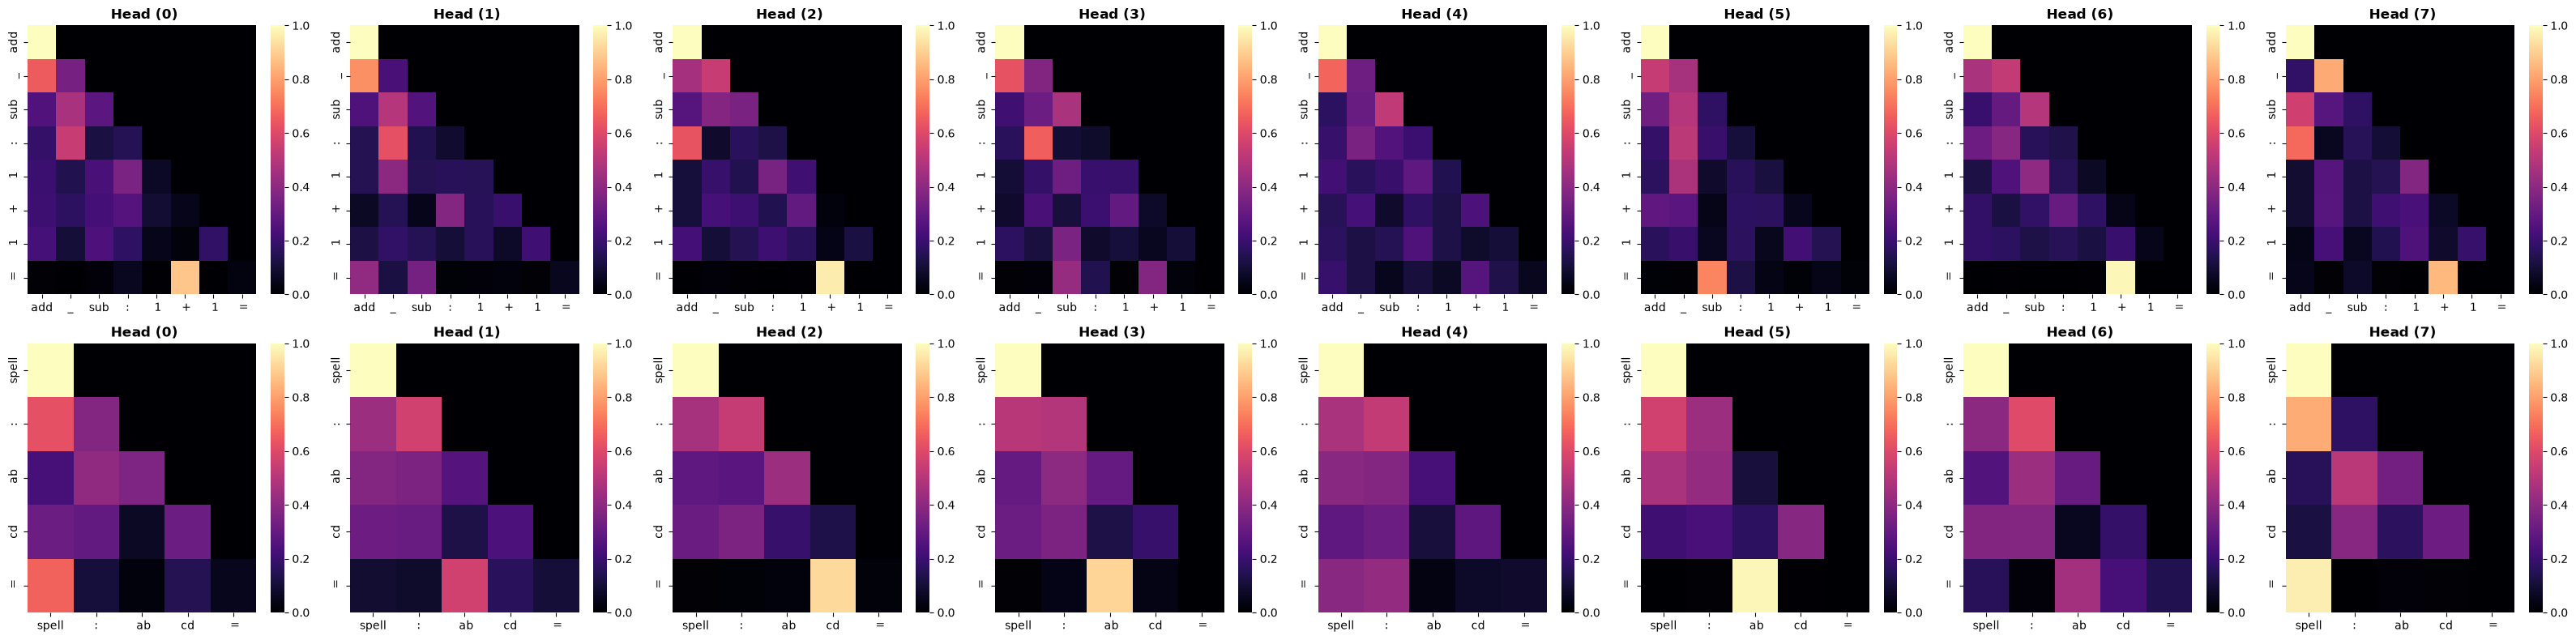

attention_results: [[{'position': 0, 'token': 'add', 'att': tensor(0.3345)}, {'position': 1, 'token': '_', 'att': tensor(0.2367)}, {'position': 2, 'token': 'sub', 'att': tensor(0.1505)}], [{'position': 0, 'token': 'spell', 'att': tensor(0.4830)}, {'position': 1, 'token': ':', 'att': tensor(0.2561)}, {'position': 2, 'token': ' ab', 'att': tensor(0.1595)}]]
ATTENTION EXPERIMENT
 Dealing with (add_sub: 1 + 1)
    ·Aspect of labels -> ['add', '_', 'sub', ':', ' 1', ' +', ' 1', ' =']
    ·Shape of labels -> 8
  ·Aspect of the att weights: torch.Size([8, 8, 8])
DEBUG (get_most_attented_tokens)
TOKEN -->{'position': 0, 'token': 'add', 'att': tensor(0.3191)}
TOKEN -->{'position': 1, 'token': '_', 'att': tensor(0.2756)}
TOKEN -->{'position': 2, 'token': 'sub', 'att': tensor(0.1158)}
 Dealing with (spell: abcd)
    ·Aspect of labels -> ['spell', ':', ' ab', 'cd', ' =']
    ·Shape of labels -> 5
  ·Aspect of the att weights: torch.Size([8, 5, 5])
DEBUG (get_most_attented_tokens)
TOKEN -->{'positi

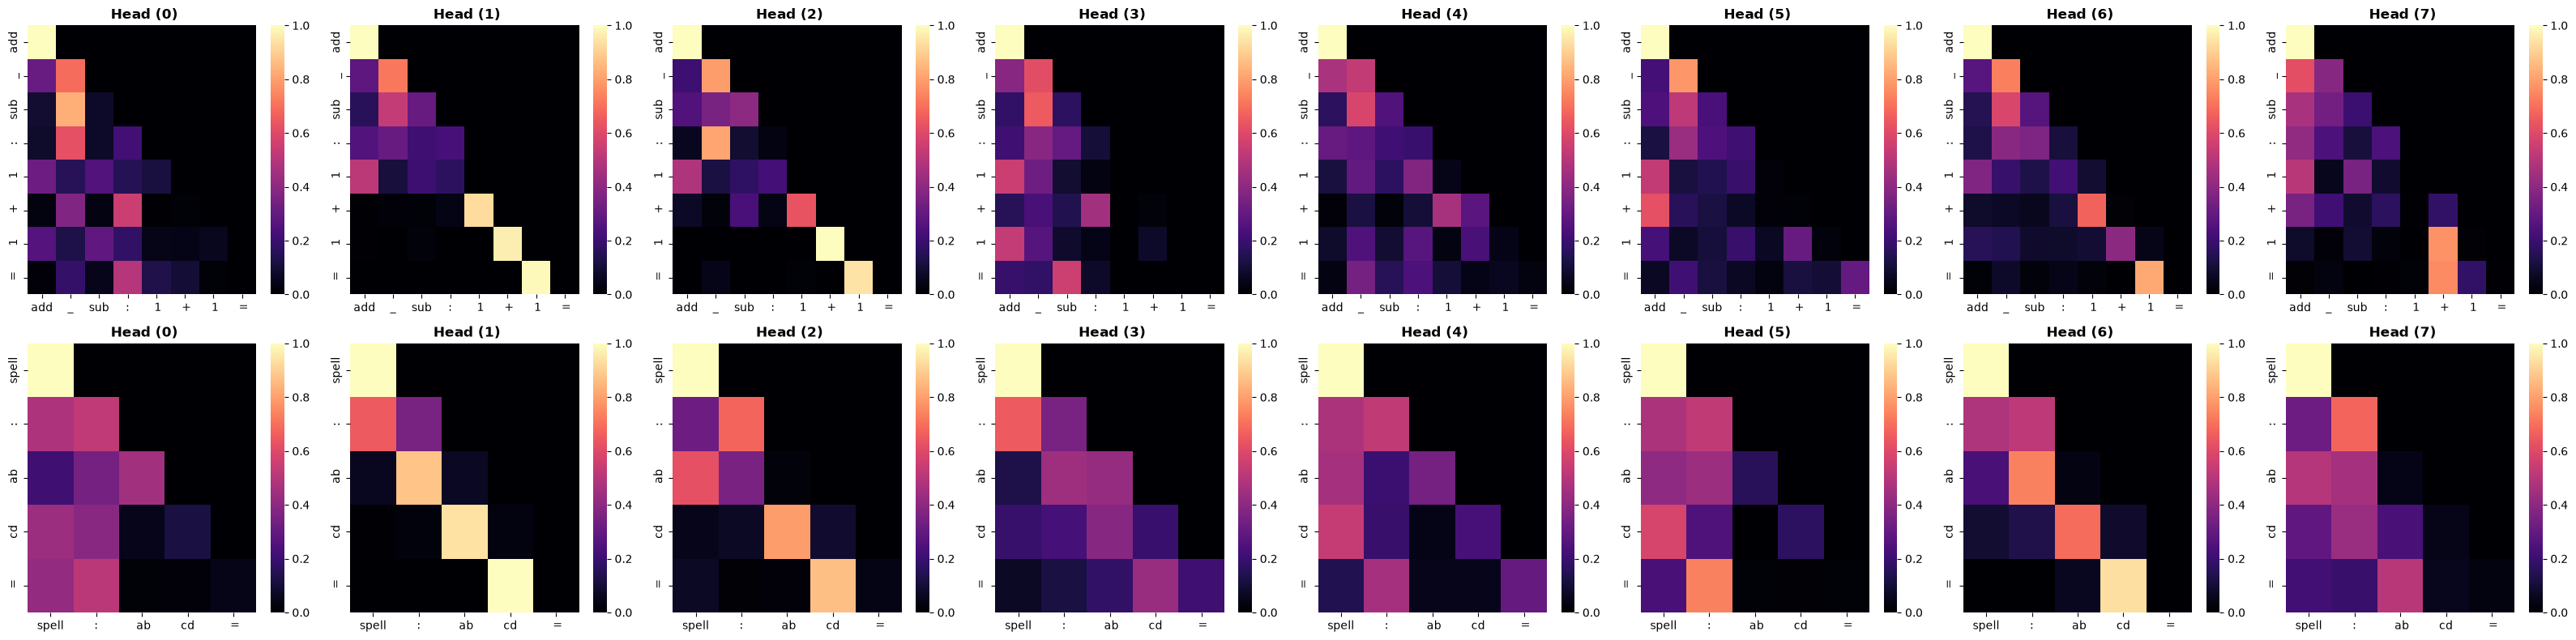

attention_results: [[{'position': 0, 'token': 'add', 'att': tensor(0.3191)}, {'position': 1, 'token': '_', 'att': tensor(0.2756)}, {'position': 2, 'token': 'sub', 'att': tensor(0.1158)}], [{'position': 0, 'token': 'spell', 'att': tensor(0.4450)}, {'position': 1, 'token': ':', 'att': tensor(0.2937)}, {'position': 2, 'token': ' ab', 'att': tensor(0.1377)}]]
ATTENTION EXPERIMENT
 Dealing with (add_sub: 1 + 1)
    ·Aspect of labels -> ['add', '_', 'sub', ':', ' 1', ' +', ' 1', ' =']
    ·Shape of labels -> 8
  ·Aspect of the att weights: torch.Size([8, 8, 8])
DEBUG (get_most_attented_tokens)
TOKEN -->{'position': 0, 'token': 'add', 'att': tensor(0.3044)}
TOKEN -->{'position': 1, 'token': '_', 'att': tensor(0.2440)}
TOKEN -->{'position': 4, 'token': ' 1', 'att': tensor(0.1167)}
 Dealing with (spell: abcd)
    ·Aspect of labels -> ['spell', ':', ' ab', 'cd', ' =']
    ·Shape of labels -> 5
  ·Aspect of the att weights: torch.Size([8, 5, 5])
DEBUG (get_most_attented_tokens)
TOKEN -->{'positio

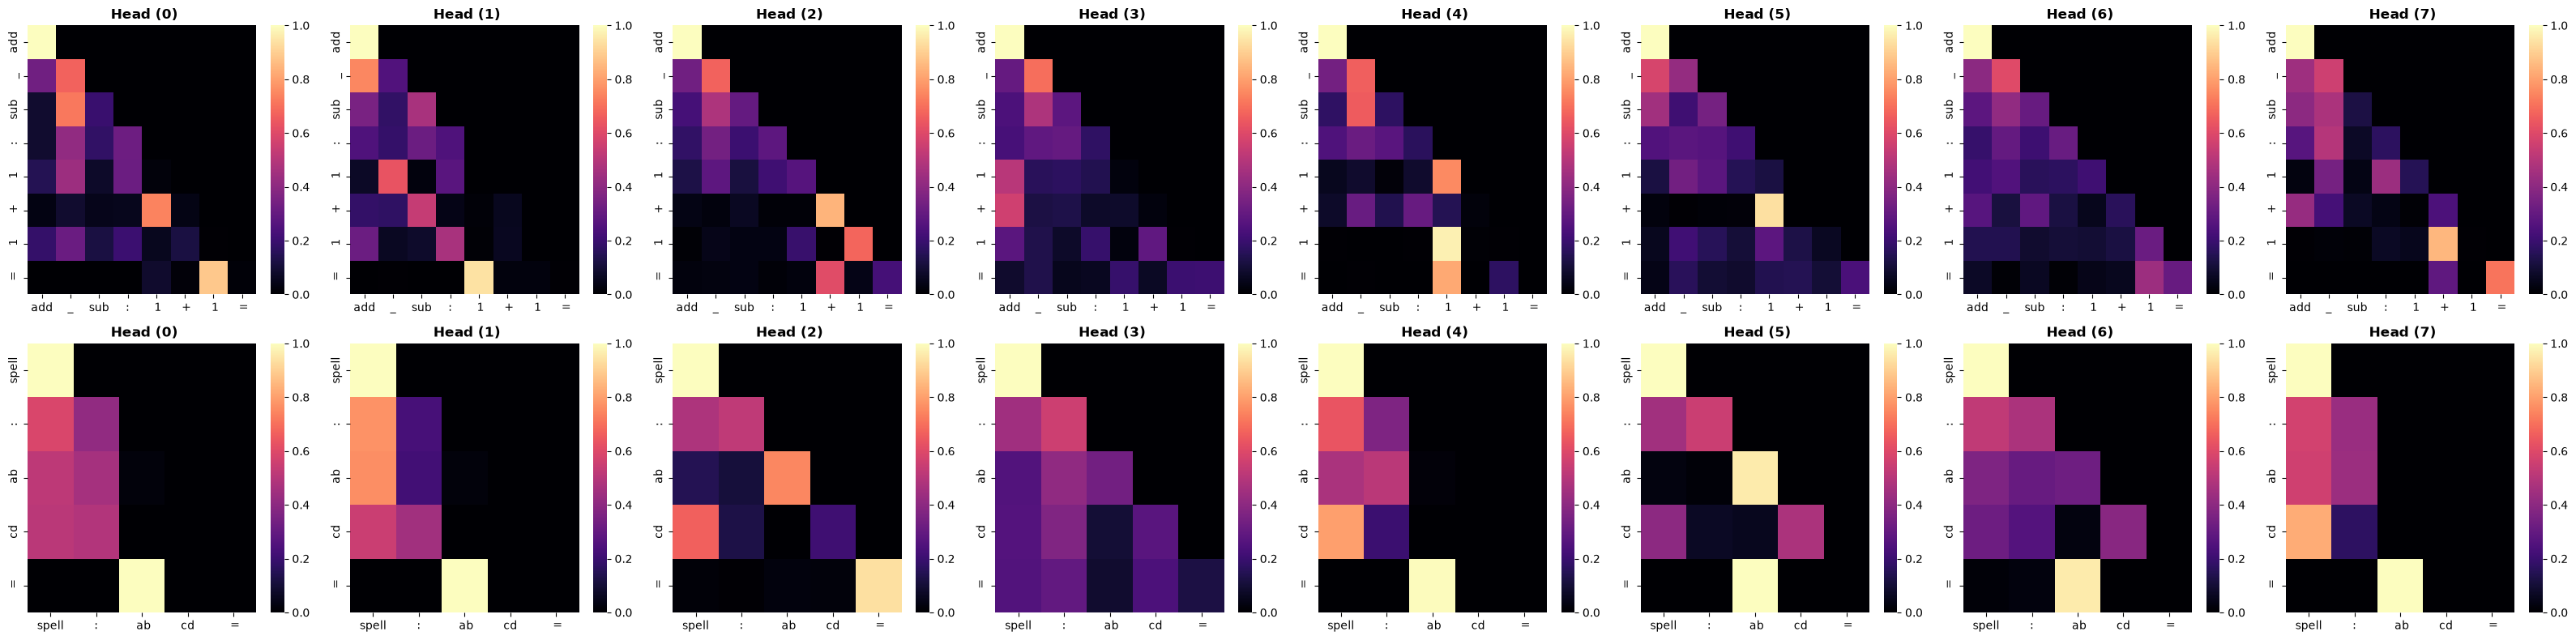

attention_results: [[{'position': 0, 'token': 'add', 'att': tensor(0.3044)}, {'position': 1, 'token': '_', 'att': tensor(0.2440)}, {'position': 4, 'token': ' 1', 'att': tensor(0.1167)}], [{'position': 0, 'token': 'spell', 'att': tensor(0.5048)}, {'position': 2, 'token': ' ab', 'att': tensor(0.2168)}, {'position': 1, 'token': ':', 'att': tensor(0.2114)}]]
ATTENTION EXPERIMENT
 Dealing with (add_sub: 1 + 1)
    ·Aspect of labels -> ['add', '_', 'sub', ':', ' 1', ' +', ' 1', ' =']
    ·Shape of labels -> 8
  ·Aspect of the att weights: torch.Size([8, 8, 8])
DEBUG (get_most_attented_tokens)
TOKEN -->{'position': 0, 'token': 'add', 'att': tensor(0.3071)}
TOKEN -->{'position': 1, 'token': '_', 'att': tensor(0.2331)}
TOKEN -->{'position': 2, 'token': 'sub', 'att': tensor(0.1544)}
 Dealing with (spell: abcd)
    ·Aspect of labels -> ['spell', ':', ' ab', 'cd', ' =']
    ·Shape of labels -> 5
  ·Aspect of the att weights: torch.Size([8, 5, 5])
DEBUG (get_most_attented_tokens)
TOKEN -->{'positio

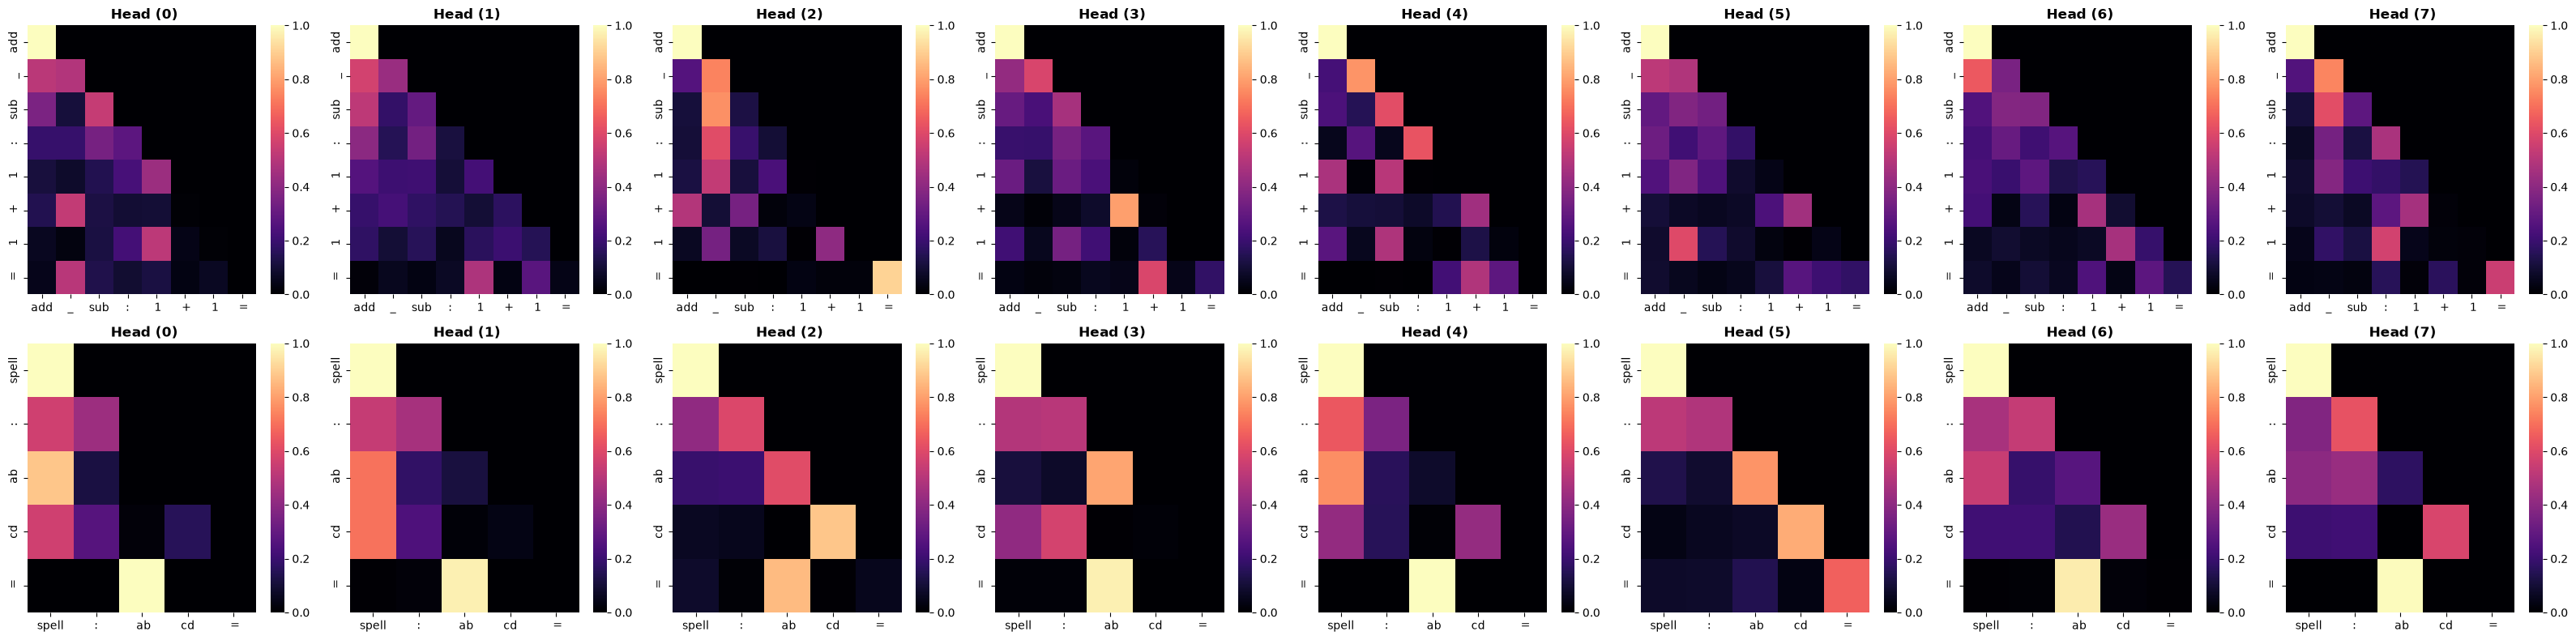

attention_results: [[{'position': 0, 'token': 'add', 'att': tensor(0.3071)}, {'position': 1, 'token': '_', 'att': tensor(0.2331)}, {'position': 2, 'token': 'sub', 'att': tensor(0.1544)}], [{'position': 0, 'token': 'spell', 'att': tensor(0.4631)}, {'position': 2, 'token': ' ab', 'att': tensor(0.2499)}, {'position': 1, 'token': ':', 'att': tensor(0.1835)}]]
ATTENTION EXPERIMENT
 Dealing with (add_sub: 1 + 1)
    ·Aspect of labels -> ['add', '_', 'sub', ':', ' 1', ' +', ' 1', ' =']
    ·Shape of labels -> 8
  ·Aspect of the att weights: torch.Size([8, 8, 8])
DEBUG (get_most_attented_tokens)
TOKEN -->{'position': 0, 'token': 'add', 'att': tensor(0.3230)}
TOKEN -->{'position': 1, 'token': '_', 'att': tensor(0.2227)}
TOKEN -->{'position': 2, 'token': 'sub', 'att': tensor(0.1554)}
 Dealing with (spell: abcd)
    ·Aspect of labels -> ['spell', ':', ' ab', 'cd', ' =']
    ·Shape of labels -> 5
  ·Aspect of the att weights: torch.Size([8, 5, 5])
DEBUG (get_most_attented_tokens)
TOKEN -->{'positi

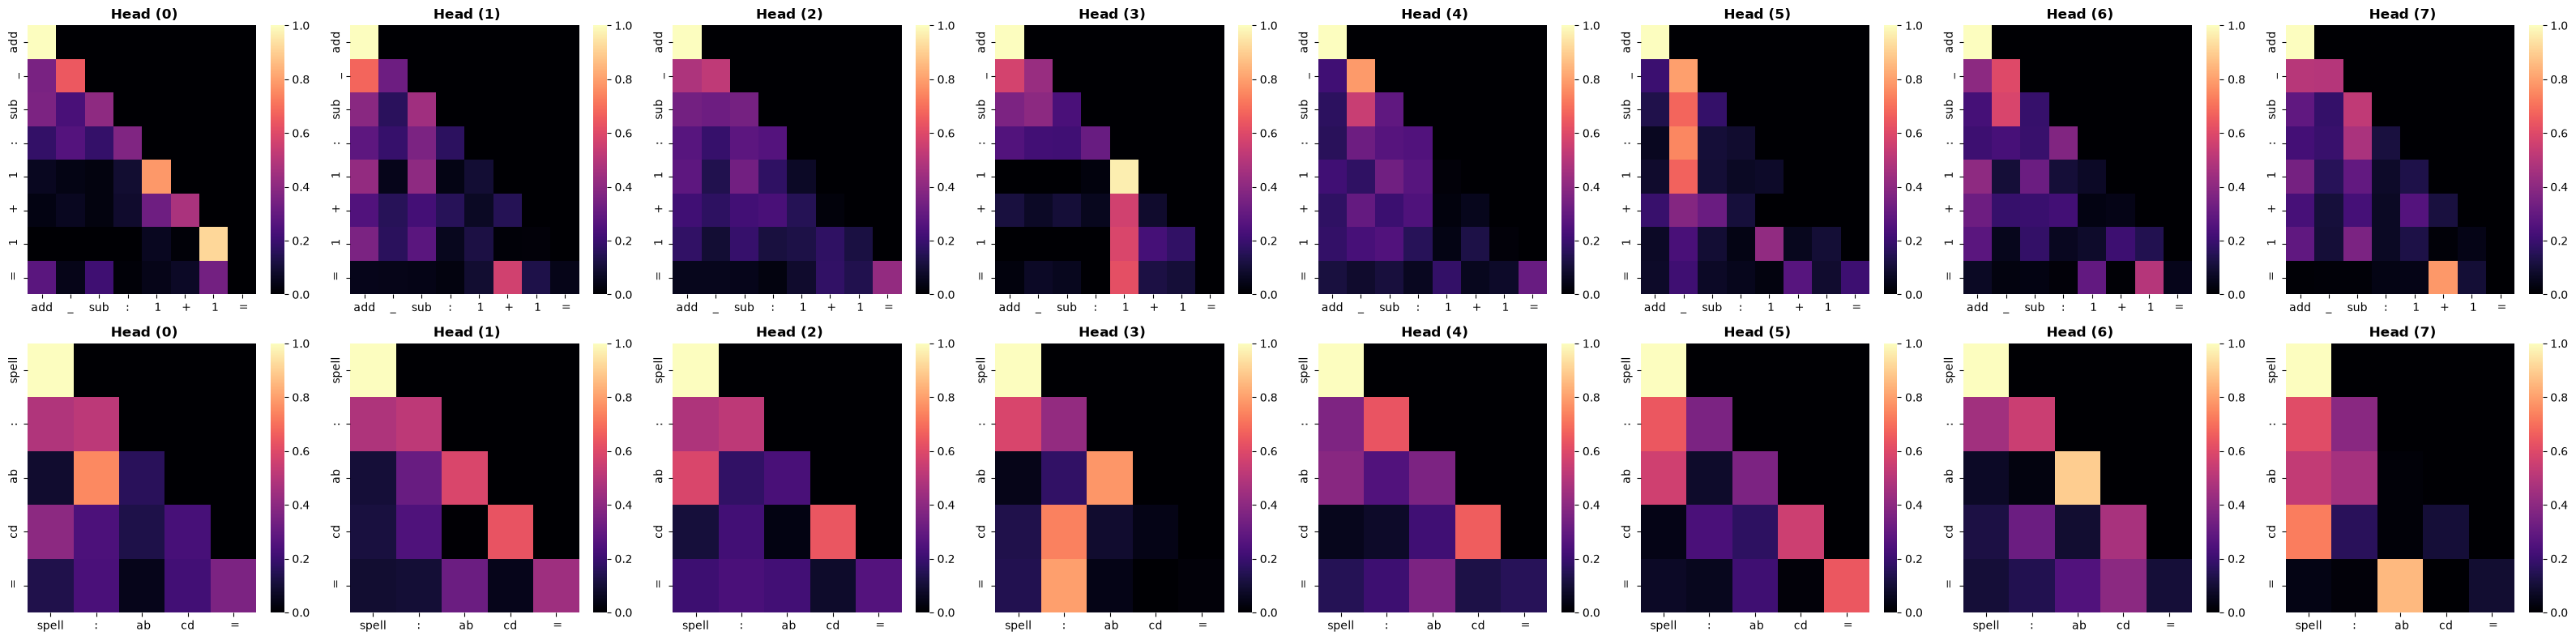

attention_results: [[{'position': 0, 'token': 'add', 'att': tensor(0.3230)}, {'position': 1, 'token': '_', 'att': tensor(0.2227)}, {'position': 2, 'token': 'sub', 'att': tensor(0.1554)}], [{'position': 0, 'token': 'spell', 'att': tensor(0.4278)}, {'position': 1, 'token': ':', 'att': tensor(0.2542)}, {'position': 2, 'token': ' ab', 'att': tensor(0.1609)}]]


In [ ]:
# Attention results_storage
att_storage = {model:[] for model in models.keys()}

# Define pairs to check
pairs = [('add_sub', "1 + 1"), ('spell', "abcd")]

# Iterate over models
for modelname, model in models.items():
    # Info print
    print(f'WORKING WITH ({modelname})')
    # Get layers
    layers  = [i for i, block in enumerate(model.trf_blocks) if block.use_moe]
    # Iterate over layers
    for layer in (layers):
        # Define params
        max_new = 30
        filename = 'layer_{layer}'

        # Call the function
        result = track_attention(model = model, modelname = modelname, pairs = pairs, layer = layer, device = device, max_new = max_new, filename = filename.format(layer = layer))

        # Store most attented tokens
        att_storage[modelname] = result



#### **ASSIGNATION ABLATION**

In [196]:
# Define tokenizer
tokenizer = Tokenizer(
    embedding_dim=768,
    max_seq_len=model.pos_emb.num_embeddings
)

In [197]:
# Most important tokens
att_storage

{'E2': [[{'position': 0, 'token': 'add', 'att': tensor(0.3342)},
   {'position': 1, 'token': '_', 'att': tensor(0.1997)},
   {'position': 2, 'token': 'sub', 'att': tensor(0.1297)}],
  [{'position': 0, 'token': 'spell', 'att': tensor(0.4003)},
   {'position': 2, 'token': ' ab', 'att': tensor(0.3860)},
   {'position': 1, 'token': ':', 'att': tensor(0.1349)}]],
 'E3': [[{'position': 0, 'token': 'add', 'att': tensor(0.3230)},
   {'position': 1, 'token': '_', 'att': tensor(0.2227)},
   {'position': 2, 'token': 'sub', 'att': tensor(0.1554)}],
  [{'position': 0, 'token': 'spell', 'att': tensor(0.4278)},
   {'position': 1, 'token': ':', 'att': tensor(0.2542)},
   {'position': 2, 'token': ' ab', 'att': tensor(0.1609)}]]}

In [ ]:
# Original pairs and modded ones
pairs = [('add_sub', "1 + 1"), ('spell', "abcd")]

**First Example**

DEBUG
·Input shape: torch.Size([8])
·Output shape: torch.Size([1])
·Cat shape: torch.Size([1, 9])
·Routes shape: torch.Size([1, 9, 2])
DEBUG
·Input shape: torch.Size([8])
·Output shape: torch.Size([0])
·Cat shape: torch.Size([1, 8])
·Routes shape: torch.Size([1, 8, 2])


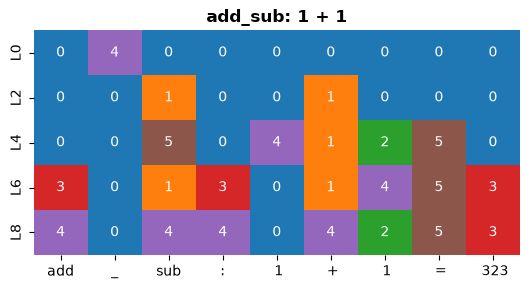

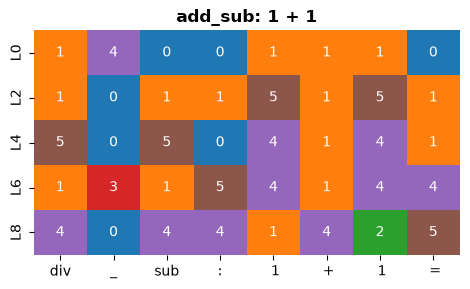

In [ ]:
# Selected model
model = full_alternate

# Define the pairs
task = 'add_sub'
prompt =  "1 + 1"

# Get og seg
prompt_ids = torch.tensor(tokenizer.encode(TaskDataset.build_prompt(prompt, task)),
                          device = device)

# Modify identified main position
idx = 0
replacement = tokenizer.encode('div')[0]
mod_ids = prompt_ids.clone()
mod_ids[idx] = replacement

# Call base routing
trace_original = token_trace(
    model, prompt, task, device
)

# Call mock routing
trace_modified = token_trace(
    model, prompt, task, device,
    input_ids = mod_ids
)

**Second Example**

DEBUG
·Input shape: torch.Size([8])
·Output shape: torch.Size([1])
·Cat shape: torch.Size([1, 9])
·Routes shape: torch.Size([1, 9, 2])
DEBUG
·Input shape: torch.Size([8])
·Output shape: torch.Size([1])
·Cat shape: torch.Size([1, 9])
·Routes shape: torch.Size([1, 9, 2])


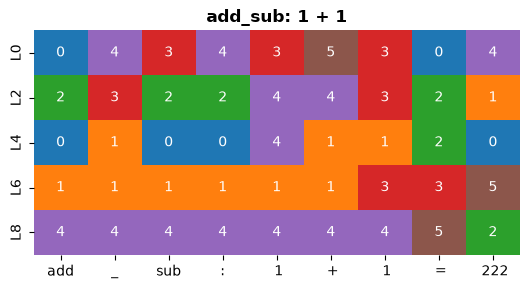

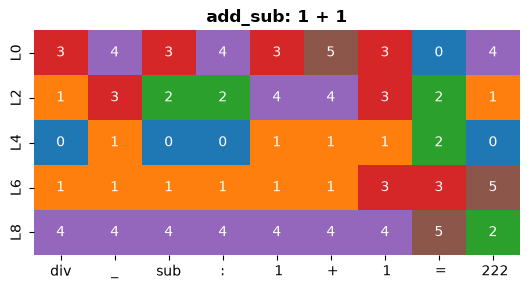

In [ ]:
# Selected model
model = full_alternate_joint

# Define the pairs
task = 'add_sub'
prompt =  "1 + 1"

# Get og seg
prompt_ids = torch.tensor(tokenizer.encode(TaskDataset.build_prompt(prompt, task)),
                          device = device)

# Modify identified main position
idx = 0
replacement = tokenizer.encode('div')[0]
mod_ids = prompt_ids.clone()
mod_ids[idx] = replacement

# Call base routing
trace_original = token_trace(
    model, prompt, task, device
)

# Call mock routing
trace_modified = token_trace(
    model, prompt, task, device,
    input_ids = mod_ids
)

In [66]:
def counterfactual_routing(model:GPTMOE, examples:list[tuple[str, str]], tasks:list[str], device:str)->pd.DataFrame:
    """
        Function aimed to measure how much the routing depends
        on the task name. The same prompt is fed with every task
        name and the top-1 expert of the shared tokens is compared
        against the original one

        Params:
            model(GPTMOE):
                The model to inspect
            examples(list(tuple(str, str))):
                (prompt, original task) pairs
            tasks(list(str)):
                The task names to swap
            device(str):
                The selected device

        Returns:
            changes(pd.DataFrame):
                Ratio of shared tokens that change expert
                per layer (rows) and example (cols)
    """
    # Build the tokenizer
    tokenizer = Tokenizer(embedding_dim = 768, max_seq_len = model.pos_emb.num_embeddings)
    model.to(device = device)
    changes = {}

    # Iterate over examples
    for prompt, task in examples:
        # Shared tokens -> everything after the task name (' <prompt> =')
        n_shared = len(tokenizer.encode(f' {prompt} ='))

        # Original routing over the shared tokens
        ids = torch.tensor([tokenizer.encode(TaskDataset.build_prompt(prompt, task))])
        reference = {layer: selected[0, -n_shared:, 0] for layer, selected in route(model, ids, device).items()}

        # Swap the task name and compare
        ratios = []
        for other in tasks:
            if other == task:
                continue
            ids = torch.tensor([tokenizer.encode(TaskDataset.build_prompt(prompt, other))])
            swapped = route(model, ids, device)
            ratios.append({layer: (selected[0, -n_shared:, 0] != reference[layer]).float().mean().item()
                           for layer, selected in swapped.items()})

        # Mean over the swapped task names
        changes[f'{task}: {prompt}'] = pd.DataFrame(ratios).mean()

    return pd.DataFrame(changes)

In [67]:
# Define params
examples = [("3612 - 7360", "add_sub"), ("254769 / 521", "mul_div"), ("P u d V", "alphabetic"),
            ("6w#B", "spell"), ("409", "parity"), ("PudV", "first_last")]

# Call the function per model
for modelname, model in models.items():
    changes = counterfactual_routing(model = model, examples = examples, tasks = tasks, device = device)
    print(f'MODEL({modelname})\n', changes, '\n')
    print(f'    (cf) Mean change ratio: {changes.values.mean():.3f}\n')

MODEL(E2)
    add_sub: 3612 - 7360  mul_div: 254769 / 521  alphabetic: P u d V  \
0              0.766667               0.714286                 1.00   
2              0.833333               0.771429                 0.68   
4              0.866667               0.828571                 0.48   
6              0.833333               0.771429                 0.56   
8              0.700000               0.771429                 0.44   

   spell: 6w#B  parity: 409  first_last: PudV  
0         1.00          0.8              1.00  
2         0.92          1.0              0.90  
4         0.84          0.7              0.85  
6         0.88          0.8              0.80  
8         0.80          0.8              0.75   

    (cf) Mean change ratio: 0.795

MODEL(E3)
    add_sub: 3612 - 7360  mul_div: 254769 / 521  alphabetic: P u d V  \
0              0.033333               0.057143                 0.12   
2              0.166667               0.114286                 0.36   
4            